# Práctica B2-2 · Escenarios de estrés y cambios de régimen de mercado
**Módulo de Gestión de Riesgos · Máster MIAX**

Este notebook construye, de principio a fin, un motor de *stress testing* con cambios de régimen:

1. **Datos** diarios de EE. UU. desde 2006 (15 acciones/ETF, HYG y los bonos del Tesoro a 10 y 2 años) con auditoría de calidad.
2. **Régimen de mercado** (calma/crisis) con un *Hidden Markov Model* gaussiano de 2 estados.
3. **Marginales condicionales** por activo y estado (Normal frente a Student-t).
4. **Cópulas** por estado (Gauss frente a t) y contraste de «las correlaciones tienden a 1».
5. **Simulador Monte Carlo** (10.000 trayectorias × 126 días) y su validación frente a los datos reales.
6. **Tres escenarios de estrés** (estanflación 2022, crisis de crédito 2008 y pánico de liquidez crediticia) con VaR y ES al 99 %.

**Cómo leerlo.** El código del motor está incrustado al principio (una celda por módulo, con comentarios) para que este
único fichero sea autocontenido; después, cada sección ejecuta una fase y explica **qué se ve y por qué importa**.
El notebook no necesita red: incluye una instantánea de los datos descargados (ver sección de datos).

**Reglas de diseño.** Interpretabilidad ante todo: no hay Deep Learning ni cajas negras (solo HMM, cópulas, Monte Carlo y estadística descriptiva);
una única semilla propaga todo el azar (mismo *seed*, mismos resultados); cada paso deja una traza al final.

In [1]:
from __future__ import annotations

import base64, gzip, json, os, sys, time, types, warnings
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import Any, Iterator, Protocol, Sequence
from contextlib import contextmanager

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.dpi"] = 100

pct = lambda x, d=1: f"{100 * x:.{d}f} %".replace(".", ",")  # Porcentaje con coma decimal.


## 0. Motor de cálculo (código de `src/stresslab` incrustado)
Cada celda de código de esta sección es un módulo del paquete, en orden de dependencia. Los módulos se envuelven en una función
para conservar sus espacios de nombres (`config.SEED`, `regimes.fit_hmm`, …) sin imports locales. **Se pueden saltar en una primera lectura**:
las secciones 1-7 usan estas funciones y comentan los resultados.

* **Capa de datos**: contratos (`Protocol`), caché CSV, proveedores de Yahoo Finance y FRED (solo se usan si se pide actualizar), auditoría y retornos.
* **Capa de dominio**: factores, regímenes, marginales, cópulas, simulador, cartera, riesgo, escenarios y validación.
* **Orquestación y figuras**: traza por paso y pipeline.

In [2]:
# === módulo: config.py ===
def _modulo_config():
    """Configuración central. Cada parámetro lleva su justificación."""

    import os
    from pathlib import Path

    import numpy as np

    # Semilla única: todo el azar sale de aquí vía numpy.random.Generator (reproducibilidad, R-TRV-03).
    SEED: int = 20260215

    # Inicio exigido por el enunciado (R-DAT-01); incluye la crisis de 2008 para el escenario E2.
    START_DATE: str = "2006-01-01"

    # Equities del universo (R-DAT-02), ya ajustados por splits y dividendos.
    EQUITIES: tuple[str, ...] = (
        "AAPL", "AMZN", "BAC", "BRK-B", "CVX", "ENPH", "GLD", "GME",
        "GOOGL", "JNJ", "JPM", "MSFT", "NVDA", "PG", "XOM",
    )

    # Crédito: el activo «HYG (BAMLH0A0HYM2)» es la serie OAS de FRED (respuesta del profesor, D-02); se convierte
    # en retorno con carry + duración de spread (ver CREDIT_SPREAD_DURATION). El ETF HYG de Yahoo se conserva
    # solo como contraste de la proxy (no entra en la cartera). Bonos 10a/2a vía FRED (D-03).
    CREDIT_ASSET: str = "HYG"
    CREDIT_ETF: str = "HYG"

    # Duración efectiva del crédito high yield respecto a su rendimiento (OAS + tipo libre de riesgo): 4 años.
    # Coincide con el valor típico del índice ICE BofA US High Yield y con la estimada por MCO contra el ETF HYG
    # (≈ 3,9 en 2007-2026; 3,8 antes de 2020 y 4,1 desde 2020). Ignora convexidad y pérdidas por impago (D-39).
    CREDIT_SPREAD_DURATION: float = 4.0
    FRED_SERIES: dict[str, str] = {"UST10Y": "DGS10", "UST2Y": "DGS2"}

    # Spread de crédito OAS de ICE BofA US High Yield (FRED): factor de estado, no activo (D-02).
    CREDIT_OAS: str = "BAMLH0A0HYM2"

    # Duración/convexidad de los bonos par sintéticos: vencimiento en años (10a y 2a, enunciado) (D-03).
    BOND_MATURITIES: dict[str, float] = {"UST10Y": 10.0, "UST2Y": 2.0}

    # Cupones semestrales: convención de los Treasuries; fija duración y convexidad del bono par.
    BOND_COUPON_FREQ: int = 2

    # Umbral de outlier: retorno a más de 8 sigmas robustas (MAD). Alto a propósito, para no eliminar
    # colas reales (GME 2021 se marca pero no se borra; spec §3).
    OUTLIER_MAD_Z: float = 8.0

    # Un salto diario de más del 40 % sin explicación sugiere split mal ajustado; se revisa a mano.
    JUMP_THRESHOLD: float = 0.40

    # Una historia que arranca más de 30 días tras START_DATE se considera corta (ENPH 2012, HYG 2007).
    SHORT_HISTORY_DAYS: int = 30

    # Proxy de mercado y volatilidad para los factores de estado (D-04).
    MARKET_TICKER: str = "^GSPC"
    VIX_TICKER: str = "^VIX"

    # Horizonte de simulación: 6 meses ≈ 126 días hábiles (enunciado F4).
    HORIZON_DAYS: int = 126

    # Trayectorias Monte Carlo: mínimo exigido 10.000 (R-SIM-01).
    N_SIMS: int = 10_000

    # Días hábiles por año para anualizar volatilidad y rendimientos de bonos.
    TRADING_DAYS: int = 252

    # Nivel de confianza de VaR/ES (enunciado F5; estándar de riesgo de mercado).
    VAR_LEVEL: float = 0.99

    # Estados del HMM: calma/crisis. Más estados queda fuera de alcance (spec §1).
    N_STATES: int = 2

    # HMM: covarianza completa porque los factores (acción, VIX, crédito) están correlacionados en crisis.
    HMM_COVARIANCE: str = "full"

    # Iteraciones máximas de EM: holgadas; EM converge antes con tolerancia por defecto.
    HMM_N_ITER: int = 300

    # EM es sensible a la inicialización (óptimos locales): se prueban varias semillas y gana la mayor verosimilitud.
    HMM_N_INIT: int = 10

    # Umbral de decisión dura sobre P(crisis) suavizada (D-06): 0,5 = estado más probable.
    CRISIS_THRESHOLD: float = 0.5

    # Duración mínima de un episodio en días (D-06): evita «crisis de 3 días»; un mes de mercado ≈ 21 días,
    # por eso 15 queda en el rango 10-20 de la spec. Se reporta sensibilidad.
    MIN_EPISODE_DAYS: int = 15
    MIN_EPISODE_SENSITIVITY: tuple[int, ...] = (10, 15, 20)

    # Episodios históricos conocidos para etiquetar crisis detectadas (inicio, fin, narrativa económica).
    KNOWN_EVENTS: tuple[tuple[str, str, str], ...] = (
        ("2007-07-01", "2009-06-30", "Crisis financiera global: hipotecas subprime, quiebra de Lehman, congelación del crédito"),
        ("2010-04-15", "2010-07-15", "Crisis de deuda soberana europea y «flash crash»"),
        ("2011-07-15", "2011-11-30", "Rebaja de rating de EE. UU. y contagio de la crisis europea"),
        ("2015-08-15", "2016-03-15", "Devaluación del yuan, caída del petróleo y miedo a desaceleración global"),
        ("2018-01-25", "2018-04-15", "Repunte de volatilidad (febrero 2018) y subida de tipos"),
        ("2018-10-01", "2019-01-15", "Venta masiva del 4T 2018: Fed restrictiva y guerra comercial"),
        ("2020-02-15", "2020-06-30", "Pandemia de COVID-19: parón económico y crisis de liquidez"),
        ("2020-09-01", "2020-10-31", "Venta de megacaps tecnológicas tras el rally de verano de 2020"),
        ("2023-03-01", "2023-04-15", "Quiebra de Silicon Valley Bank y estrés en bancos regionales"),
        ("2022-01-01", "2022-12-31", "Estanflación: inflación alta y subidas agresivas de tipos; caen acciones y bonos a la vez"),
        ("2025-03-01", "2025-06-15", "Aranceles de abril de 2025 y shock de incertidumbre comercial"),
    )

    # Tope de los retornos diarios simulados: ±2× el extremo histórico de cada activo (y nunca < -99 %).
    # La t con 3 g.l. tiene colas tan pesadas que unas pocas de 22 millones de extracciones serían
    # irreales (+300 %); el tope se aplica a una fracción ínfima de datos, que se reporta.
    SIM_CLIP_MULT: float = 2.0

    # Ventanas de calibración de los escenarios (D-10): E1 = año 2022 completo; E2 = septiembre 2008
    # (quiebra de Lehman) a marzo 2009 (suelo del S&P 500). Las alternativas miden la sensibilidad a la ventana.
    E1_WINDOW: tuple[str, str] = ("2022-01-01", "2022-12-31")
    E1_WINDOW_ALT: tuple[str, str] = ("2022-01-01", "2022-10-31")
    E2_WINDOW: tuple[str, str] = ("2008-09-01", "2009-03-31")
    E2_WINDOW_ALT: tuple[str, str] = ("2008-09-15", "2009-03-31")

    # Mínimo de días de crisis en la ventana para recalibrar; por debajo se usan todos los días de la ventana.
    SCEN_MIN_OBS: int = 60

    # E3 «pánico de liquidez crediticia» (D-11): volatilidad ×1,5; t de 3 g.l. (la más gruesa admitida)
    # y correlaciones R' = (1-λ)R + λJ con λ = 0,3 (recetas de la spec §5.5).
    E3_VOL_MULT: float = 1.5
    E3_COPULA_DF: float = 3.0
    E3_LAMBDA: float = 0.3

    # Trayectorias de las sensibilidades: menos que las 10.000 oficiales para acotar el tiempo de cálculo.
    SENS_SIMS: int = 3000

    # Ruido idiosincrático de la proxy de ENPH multiplicado en la sensibilidad de E2.
    PROXY_NOISE_MULT: float = 2.0

    # Rutas del proyecto.
    ROOT: Path = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # En el notebook no hay __file__: la raíz es la carpeta que contiene notebooks/ (o el directorio actual).
    RAW_DIR: Path = ROOT / "data" / "raw"
    OUTPUT_DIR: Path = ROOT / "outputs"


    def rng(seed: int | None = None) -> np.random.Generator:
        """Generador reproducible; sin argumento usa la semilla única SEED."""
        return np.random.default_rng(SEED if seed is None else seed)


    def is_offline() -> bool:
        """Modo offline: OFFLINE=true o caché en data/raw/ (spec §4, regla 2)."""
        if os.environ.get("OFFLINE", "").strip().lower() in {"1", "true", "yes"}:
            return True
        return RAW_DIR.is_dir() and any(RAW_DIR.glob("*.csv"))
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

config = _modulo_config()
del _modulo_config


In [3]:
# === módulo: data/base.py ===
def _modulo_base():
    """Protocols de datos: único contrato del que depende la lógica de negocio."""

    from typing import Protocol, Sequence

    import pandas as pd


    class PriceProvider(Protocol):
        """Precios ajustados diarios; columnas = tickers, índice = fechas."""

        def get_prices(self, tickers: Sequence[str], start: str, end: str | None = None) -> pd.DataFrame:
            ...


    class RateProvider(Protocol):
        """Rendimientos (en %) diarios de series de tipos; columnas = series."""

        def get_rates(self, series: Sequence[str], start: str, end: str | None = None) -> pd.DataFrame:
            ...
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

base = _modulo_base()
del _modulo_base


In [4]:
# === módulo: data/csv_cache.py ===
def _modulo_csv_cache():
    """Caché CSV en data/raw: lectura/escritura y proveedor offline."""

    from pathlib import Path
    from typing import Sequence

    import pandas as pd

    pass  # import local sustituido por el espacio de nombres del notebook

    PRICES_FILE = "prices.csv"  # Equities, HYG, ^GSPC y ^VIX (precios ajustados).
    RATES_FILE = "rates.csv"  # DGS10, DGS2 y OAS (en %).


    def read_csv(name: str, raw_dir: Path = config.RAW_DIR) -> pd.DataFrame:
        """Lee un CSV de la caché con índice de fechas."""
        path = raw_dir / name
        if not path.exists():
            raise FileNotFoundError(f"Falta {path}; ejecuta scripts/fetch_data.py o scripts/migrate_bronze.py")
        return pd.read_csv(path, index_col=0, parse_dates=True).sort_index()


    def update_csv(name: str, df: pd.DataFrame, raw_dir: Path = config.RAW_DIR) -> Path:
        """Fusiona df con la caché existente (lo nuevo prevalece) y la guarda."""
        raw_dir.mkdir(parents=True, exist_ok=True)
        path = raw_dir / name
        merged = df.combine_first(read_csv(name, raw_dir)) if path.exists() else df
        merged.sort_index().to_csv(path, index_label="Date")
        return path


    class CsvProvider:
        """PriceProvider y RateProvider sobre data/raw (cero red)."""

        def __init__(self, raw_dir: Path = config.RAW_DIR) -> None:
            self.raw_dir = raw_dir

        def _select(self, name: str, cols: Sequence[str], start: str, end: str | None) -> pd.DataFrame:
            df = read_csv(name, self.raw_dir)
            faltan = [c for c in cols if c not in df.columns]
            if faltan:
                raise KeyError(f"{name} no contiene {faltan}")
            return df.loc[start:end, list(cols)]

        def get_prices(self, tickers: Sequence[str], start: str = config.START_DATE,
                       end: str | None = None) -> pd.DataFrame:
            """Precios desde la caché."""
            return self._select(PRICES_FILE, tickers, start, end)

        def get_rates(self, series: Sequence[str], start: str = config.START_DATE,
                      end: str | None = None) -> pd.DataFrame:
            """Rendimientos (%) desde la caché."""
            return self._select(RATES_FILE, series, start, end)
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

csv_cache = _modulo_csv_cache()
del _modulo_csv_cache


In [5]:
# === módulo: data/fred.py ===
def _modulo_fred():
    """Proveedor FRED. Único módulo (con yahoo.py) que toca la red junto a Yahoo."""

    import os
    from typing import Sequence

    import pandas as pd
    from fredapi import Fred

    pass  # import local sustituido por el espacio de nombres del notebook

    # Endpoint público de FRED que no requiere clave (se usa si falta FRED_API_KEY).
    _PUBLIC_CSV = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={id}"


    class FredRateProvider:
        """Series diarias de FRED en %. Clave solo por variable de entorno FRED_API_KEY."""

        def __init__(self) -> None:
            key = os.environ.get("FRED_API_KEY", "").strip()
            self._client = Fred(api_key=key) if key else None

        def _one(self, series_id: str, start: str, end: str | None) -> pd.Series:
            if self._client is not None:
                s = self._client.get_series(series_id, observation_start=start, observation_end=end)
            else:
                df = pd.read_csv(_PUBLIC_CSV.format(id=series_id), index_col=0, parse_dates=True,
                                 na_values=["."])
                s = df.iloc[:, 0].loc[start:end]
            s.index = pd.to_datetime(s.index)
            return pd.to_numeric(s, errors="coerce").rename(series_id)

        def get_rates(self, series: Sequence[str], start: str = config.START_DATE,
                      end: str | None = None) -> pd.DataFrame:
            """Descarga cada serie y las alinea por fecha."""
            return pd.concat([self._one(s, start, end) for s in series], axis=1)
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

try:
    fred = _modulo_fred()
except ImportError as _e:  # Librería de red ausente: el notebook sigue con la caché.
    fred = None
    warnings.warn(f"data/fred.py: no se pudo importar ({_e}); solo se usará la caché")
del _modulo_fred


In [6]:
# === módulo: data/yahoo.py ===
def _modulo_yahoo():
    """Proveedor de precios Yahoo Finance. Único módulo (con fred.py) que toca la red."""

    from typing import Sequence

    import pandas as pd
    import yfinance as yf

    pass  # import local sustituido por el espacio de nombres del notebook


    class YahooPriceProvider:
        """Precios ajustados por splits y dividendos (auto_adjust=True)."""

        def get_prices(self, tickers: Sequence[str], start: str = config.START_DATE,
                       end: str | None = None) -> pd.DataFrame:
            """Descarga Close ajustado; lanza error si el resultado está vacío."""
            raw = yf.download(list(tickers), start=start, end=end, auto_adjust=True,
                              progress=False, group_by="column")
            if raw is None or raw.empty:
                raise RuntimeError("Yahoo Finance devolvió datos vacíos")
            close = raw["Close"]
            if isinstance(close, pd.Series):
                close = close.to_frame(list(tickers)[0])
            close.index = pd.to_datetime(close.index).tz_localize(None)
            return close[list(tickers)]
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

try:
    yahoo = _modulo_yahoo()
except ImportError as _e:  # Librería de red ausente: el notebook sigue con la caché.
    yahoo = None
    warnings.warn(f"data/yahoo.py: no se pudo importar ({_e}); solo se usará la caché")
del _modulo_yahoo


In [7]:
# === módulo: data/loader.py ===
def _modulo_loader():
    """Carga con degradación elegante: fuente viva -> caché CSV, avisando del fallo."""

    import warnings
    from dataclasses import dataclass, field
    from pathlib import Path
    from typing import Callable

    import pandas as pd

    pass  # import local sustituido por el espacio de nombres del notebook
    pass  # import local sustituido por el espacio de nombres del notebook
    PriceProvider = base.PriceProvider
    RateProvider = base.RateProvider

    PRICE_TICKERS: tuple[str, ...] = (*config.EQUITIES, config.CREDIT_ETF, config.MARKET_TICKER, config.VIX_TICKER)
    RATE_SERIES: tuple[str, ...] = (*config.FRED_SERIES.values(), config.CREDIT_OAS)


    @dataclass
    class MarketData:
        """Datos crudos (precios y tipos) más los avisos de degradación."""

        prices: pd.DataFrame
        rates: pd.DataFrame
        warnings: list[str] = field(default_factory=list)


    def clean_prices(prices: pd.DataFrame) -> pd.DataFrame:
        """Calendario de bolsa limpio: quita festivos con solo VIX y la barra del día en curso (incompleta)."""
        out = prices.dropna(subset=[config.MARKET_TICKER])
        return out[out.index < pd.Timestamp.today().normalize()]


    def _with_fallback(live: Callable[[], pd.DataFrame], cache: Callable[[], pd.DataFrame],
                       save: Callable[[pd.DataFrame], object], label: str, avisos: list[str]) -> pd.DataFrame:
        """Intenta la fuente viva; si falla, usa la caché y avisa."""
        try:
            df = live()
            save(df)
            return df
        except Exception as exc:  # noqa: BLE001 - cualquier fallo de red degrada a caché
            msg = f"{label}: fuente viva falló ({type(exc).__name__}: {exc}); se usa la caché data/raw"
            warnings.warn(msg, stacklevel=2)
            avisos.append(msg)
            return cache()


    def load_market_data(offline: bool | None = None, raw_dir: Path = config.RAW_DIR,
                         prices: PriceProvider | None = None, rates: RateProvider | None = None) -> MarketData:
        """Carga precios y tipos. Offline => solo caché; online => viva con respaldo en caché."""
        offline = config.is_offline() if offline is None else offline
        cache = csv_cache.CsvProvider(raw_dir)
        avisos: list[str] = []
        if offline:
            return MarketData(clean_prices(cache.get_prices(PRICE_TICKERS)), cache.get_rates(RATE_SERIES), avisos)
        if prices is None or rates is None:  # Importación diferida: solo si hay red.
            FredRateProvider = fred.FredRateProvider
            YahooPriceProvider = yahoo.YahooPriceProvider
            prices, rates = prices or YahooPriceProvider(), rates or FredRateProvider()
        px = _with_fallback(lambda: prices.get_prices(PRICE_TICKERS, config.START_DATE),
                            lambda: cache.get_prices(PRICE_TICKERS), lambda d: csv_cache.update_csv(
                                csv_cache.PRICES_FILE, d, raw_dir), "precios", avisos)
        rt = _with_fallback(lambda: rates.get_rates(RATE_SERIES, config.START_DATE),
                            lambda: cache.get_rates(RATE_SERIES), lambda d: csv_cache.update_csv(
                                csv_cache.RATES_FILE, d, raw_dir), "tipos", avisos)
        return MarketData(clean_prices(px), rt, avisos)
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

loader = _modulo_loader()
del _modulo_loader


In [8]:
# === módulo: data/returns.py ===
def _modulo_returns():
    """Retornos de equities y de bonos (aproximación por duración y convexidad)."""

    import numpy as np
    import pandas as pd

    pass  # import local sustituido por el espacio de nombres del notebook


    def simple_returns(prices: pd.DataFrame) -> pd.DataFrame:
        """Retornos simples diarios; no rellena huecos (los NaN se conservan)."""
        return prices.pct_change(fill_method=None).iloc[1:]


    def par_bond_duration_convexity(y: np.ndarray, maturity: float,
                                    freq: int = config.BOND_COUPON_FREQ) -> tuple[np.ndarray, np.ndarray]:
        """Duración modificada y convexidad de un bono a la par con cupón = y (y en decimal)."""
        y = np.asarray(y, dtype=float)
        n = int(round(maturity * freq))
        k = np.arange(1, n + 1)[:, None]  # Periodos de pago.
        c = y[None, :] / freq  # Cupón por periodo = rendimiento (bono par).
        v = (1.0 + c) ** (-k)
        cash = np.where(k == n, 1.0 + c, c)  # Cupones + principal al final.
        t = k / freq
        price = (cash * v).sum(axis=0)  # = 1 por construcción.
        d_mod = (t * cash * v).sum(axis=0) / price / (1.0 + y / freq)
        conv = (cash * v * t * (t + 1.0 / freq)).sum(axis=0) / price / (1.0 + y / freq) ** 2
        return d_mod, conv


    def bond_returns(yields_pct: pd.Series, maturity: float) -> pd.Series:
        """r_t ≈ y_{t-1}/252 − D·Δy + ½·C·Δy² con D y C del bono par al rendimiento previo."""
        y = (yields_pct / 100.0).astype(float)
        prev = y.shift(1)
        dy = y - prev
        ok = prev.notna() & dy.notna()
        d_mod, conv = par_bond_duration_convexity(prev[ok].to_numpy(), maturity)
        out = pd.Series(np.nan, index=y.index)
        out[ok] = prev[ok] / config.TRADING_DAYS - d_mod * dy[ok] + 0.5 * conv * dy[ok] ** 2
        return out.iloc[1:].dropna()


    def credit_returns(oas_pct: pd.Series, riskfree_pct: pd.Series) -> pd.Series:
        """Retorno del crédito high yield: r_t ≈ y_{t-1}/252 − D·Δy_t con y = OAS + tipo libre de riesgo (D-39)."""
        y = ((oas_pct + riskfree_pct) / 100.0).astype(float)
        return (y.shift(1) / config.TRADING_DAYS - config.CREDIT_SPREAD_DURATION * y.diff()).iloc[1:].dropna()


    def asset_returns(prices: pd.DataFrame, rates: pd.DataFrame) -> pd.DataFrame:
        """Retornos de la cartera: equities (precios), HYG (OAS de FRED, D-02) y bonos 10a/2a (duración)."""
        eq = simple_returns(prices[list(config.EQUITIES)])
        tipos = rates.reindex(prices.index.union(rates.index)).ffill(limit=5).reindex(prices.index)
        libre = tipos[[config.FRED_SERIES["UST10Y"], config.FRED_SERIES["UST2Y"]]].mean(axis=1)  # Proxy de tipo a 5 años.
        credito = credit_returns(tipos[config.CREDIT_OAS], libre).rename(config.CREDIT_ASSET).reindex(eq.index)
        bonos = bond_return_table(tipos).reindex(eq.index)
        return pd.concat([eq, credito, bonos], axis=1)


    def bond_return_table(rates: pd.DataFrame) -> pd.DataFrame:
        """Retornos de los bonos de config.BOND_MATURITIES desde DGS10/DGS2."""
        cols = {name: bond_returns(rates[config.FRED_SERIES[name]].dropna(), m)
                for name, m in config.BOND_MATURITIES.items()}
        return pd.DataFrame(cols)
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

returns = _modulo_returns()
del _modulo_returns


In [9]:
# === módulo: data/audit.py ===
def _modulo_audit():
    """Auditoría de calidad: historias cortas, huecos, outliers y saltos (R-DAT-04)."""

    from dataclasses import dataclass

    import numpy as np
    import pandas as pd

    pass  # import local sustituido por el espacio de nombres del notebook
    simple_returns = returns.simple_returns


    def _robust_z(r: pd.Series) -> pd.Series:
        """Retorno en sigmas robustas (mediana y MAD escalado a normal)."""
        mad = (r - r.median()).abs().median() * 1.4826
        return (r - r.median()) / mad if mad > 0 else r * 0.0


    def audit_prices(prices: pd.DataFrame) -> pd.DataFrame:
        """Tabla de auditoría por activo; marca pero NUNCA elimina datos."""
        rets = simple_returns(prices)
        calendario = prices.index
        inicio_ref = pd.Timestamp(config.START_DATE)
        filas = {}
        for col in prices.columns:
            s = prices[col].dropna()
            r = rets[col].dropna()
            z = _robust_z(r)
            gaps = calendario[(calendario >= s.index[0]) & (calendario <= s.index[-1])].difference(s.index)
            filas[col] = {
                "inicio": s.index[0].date(), "fin": s.index[-1].date(), "n_obs": len(s),
                "historia_corta": bool((s.index[0] - inicio_ref).days > config.SHORT_HISTORY_DAYS),
                "huecos_internos": len(gaps),
                "retorno_max_abs": float(r.abs().max()), "fecha_max": r.abs().idxmax().date(),
                "n_outliers": int((z.abs() > config.OUTLIER_MAD_Z).sum()),
                "n_saltos": int((r.abs() > config.JUMP_THRESHOLD).sum()),
                "n_precios_no_positivos": int((s <= 0).sum()),
            }
        return pd.DataFrame(filas).T


    @dataclass(frozen=True)
    class ProxyModel:
        """r_i = alpha + beta·r_mercado + eps; eps con desviación por estado (o única)."""

        alpha: float
        beta: float
        resid_std: tuple[float, ...]  # Un valor por estado (uno solo si no hay estados).


    def fit_market_proxy(target: pd.Series, market: pd.Series, states: pd.Series | None = None,
                         n_states: int = config.N_STATES) -> ProxyModel:
        """Regresión MCO del activo sobre el mercado en el solape; residuo por estado si se dan."""
        df = pd.concat([target, market], axis=1, keys=["y", "x"]).dropna()
        beta, alpha = np.polyfit(df["x"], df["y"], 1)
        resid = df["y"] - (alpha + beta * df["x"])
        if states is None:
            return ProxyModel(float(alpha), float(beta), (float(resid.std()),))
        st = states.reindex(resid.index)
        stds = tuple(float(resid[st == k].std()) if (st == k).sum() > 2 else float(resid.std())
                     for k in range(n_states))
        return ProxyModel(float(alpha), float(beta), stds)


    def fill_with_proxy(target: pd.Series, market: pd.Series, model: ProxyModel,
                        rng: np.random.Generator, states: pd.Series | None = None) -> pd.Series:
        """Rellena los NaN de target con alpha + beta·mercado + ruido idiosincrático (documentado)."""
        falta = target.index[target.isna()].intersection(market.dropna().index)
        if states is None:
            sd = np.full(len(falta), model.resid_std[0])
        else:
            sd = np.array([model.resid_std[int(k)] for k in states.reindex(falta).fillna(0)])
        ruido = rng.standard_normal(len(falta)) * sd
        out = target.copy()
        out.loc[falta] = model.alpha + model.beta * market.loc[falta] + ruido
        return out
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

audit = _modulo_audit()
del _modulo_audit


In [10]:
# === módulo: domain/features.py ===
def _modulo_features():
    """Factores de estado del HMM (D-04): variaciones, no niveles, comparables a retornos."""

    import numpy as np
    import pandas as pd

    pass  # import local sustituido por el espacio de nombres del notebook

    FACTORS: tuple[str, ...] = ("ret_sp500", "dlog_vix", "d_curva_10y2y", "d_oas_hy")


    def build_features(prices: pd.DataFrame, rates: pd.DataFrame) -> pd.DataFrame:
        """S&P 500 (retorno), Δlog VIX, Δ(10a−2a) y Δ OAS HY, sobre el calendario de bolsa."""
        px = prices[[config.MARKET_TICKER, config.VIX_TICKER]].dropna()
        tipos = rates.reindex(px.index.union(rates.index)).ffill(limit=5).reindex(px.index)
        curva = tipos[config.FRED_SERIES["UST10Y"]] - tipos[config.FRED_SERIES["UST2Y"]]
        out = pd.DataFrame({
            FACTORS[0]: px[config.MARKET_TICKER].pct_change(),
            FACTORS[1]: np.log(px[config.VIX_TICKER]).diff(),
            FACTORS[2]: curva.diff(),
            FACTORS[3]: tipos[config.CREDIT_OAS].diff(),
        })
        return out.dropna()


    def standardize(x: pd.DataFrame) -> pd.DataFrame:
        """Z-score por columna (media y desviación de toda la muestra)."""
        return (x - x.mean()) / x.std()
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

features = _modulo_features()
del _modulo_features


In [11]:
# === módulo: domain/regimes.py ===
def _modulo_regimes():
    """HMM gaussiano de 2 estados: ajuste, orden calma/crisis, filtrado, duración mínima y episodios."""

    from dataclasses import dataclass

    import numpy as np
    import pandas as pd
    from hmmlearn.hmm import GaussianHMM
    from scipy.special import logsumexp
    from scipy.stats import multivariate_normal

    pass  # import local sustituido por el espacio de nombres del notebook


    @dataclass
    class RegimeFit:
        """Modelo ajustado; order[k] = índice interno de hmmlearn del estado k (0 calma, 1 crisis)."""

        model: GaussianHMM
        order: np.ndarray
        loglik: float

        @property
        def transmat(self) -> np.ndarray:
            return self.model.transmat_[np.ix_(self.order, self.order)]

        @property
        def startprob(self) -> np.ndarray:
            return self.model.startprob_[self.order]

        @property
        def means(self) -> np.ndarray:
            return self.model.means_[self.order]

        @property
        def covars(self) -> np.ndarray:
            return self.model.covars_[self.order]


    def fit_hmm(x: np.ndarray, n_states: int = config.N_STATES, n_init: int = config.HMM_N_INIT,
                seed: int | None = None) -> RegimeFit:
        """EM con varias inicializaciones; ordena estados por varianza total (0 = calma)."""
        rng = config.rng(seed)
        best: GaussianHMM | None = None
        best_ll = -np.inf
        for s in rng.integers(0, 2**31 - 1, size=n_init):
            m = GaussianHMM(n_components=n_states, covariance_type=config.HMM_COVARIANCE,
                            n_iter=config.HMM_N_ITER, random_state=int(s))
            try:
                m.fit(x)
                ll = m.score(x)
            except ValueError:  # Inicialización degenerada: se descarta.
                continue
            if ll > best_ll:
                best, best_ll = m, ll
        if best is None:
            raise RuntimeError("EM no convergió en ninguna inicialización")
        varianza = [np.trace(c) for c in best.covars_]
        return RegimeFit(best, np.argsort(varianza), float(best_ll))


    def smoothed_proba(fit: RegimeFit, x: np.ndarray) -> np.ndarray:
        """P(estado_t | toda la serie) con columnas ordenadas (usa información futura: look-ahead)."""
        return fit.model.predict_proba(x)[:, fit.order]


    def filtered_proba(fit: RegimeFit, x: np.ndarray) -> np.ndarray:
        """P(estado_t | datos hasta t): algoritmo forward, sin look-ahead."""
        mu, cov, pi, a = fit.means, fit.covars, fit.startprob, fit.transmat
        log_b = np.column_stack([multivariate_normal.logpdf(x, mu[k], cov[k]) for k in range(len(pi))])
        out = np.empty_like(log_b)
        log_alpha = np.log(pi) + log_b[0]
        out[0] = np.exp(log_alpha - logsumexp(log_alpha))
        for t in range(1, len(x)):
            log_alpha = logsumexp(np.log(out[t - 1])[:, None] + np.log(a), axis=0) + log_b[t]
            out[t] = np.exp(log_alpha - logsumexp(log_alpha))
        return out


    def _runs(s: np.ndarray) -> list[list[int]]:
        """Tramos consecutivos [inicio, fin_exclusivo, estado]."""
        cortes = np.flatnonzero(np.diff(s)) + 1
        ini = np.r_[0, cortes]
        fin = np.r_[cortes, len(s)]
        return [[int(i), int(f), int(s[i])] for i, f in zip(ini, fin)]


    def enforce_min_duration(states: np.ndarray, min_days: int) -> np.ndarray:
        """Absorbe el tramo más corto (< min_days) en el estado vecino hasta que ninguno lo sea."""
        s = states.astype(int).copy()
        while True:
            runs = _runs(s)
            if len(runs) == 1 or min(f - i for i, f, _ in runs) >= min_days:
                return s
            i, f, est = min(runs, key=lambda r: (r[1] - r[0], r[0]))
            s[i:f] = 1 - est


    def hard_states(p_crisis: np.ndarray, threshold: float = config.CRISIS_THRESHOLD,
                    min_days: int = config.MIN_EPISODE_DAYS) -> np.ndarray:
        """Decisión dura: umbral sobre P(crisis) y filtro de duración mínima."""
        return enforce_min_duration((p_crisis > threshold).astype(int), min_days)


    def transition_matrix(states: np.ndarray) -> np.ndarray:
        """Matriz de transición empírica de una secuencia 0/1."""
        n = np.zeros((2, 2))
        np.add.at(n, (states[:-1], states[1:]), 1)
        return n / n.sum(axis=1, keepdims=True)


    def regime_stats(states: np.ndarray) -> dict[str, object]:
        """% de días, duración media observada, nº de cambios, matriz y duración esperada 1/(1−pii)."""
        p = transition_matrix(states)
        runs = _runs(states)
        dur = {k: [f - i for i, f, e in runs if e == k] for k in (0, 1)}
        return {
            "pct_crisis": float(states.mean()),
            "n_cambios": len(runs) - 1,
            "duracion_media": {k: float(np.mean(v)) if v else float("nan") for k, v in dur.items()},
            "duracion_esperada": {k: float(1.0 / (1.0 - p[k, k])) if p[k, k] < 1 else float("inf") for k in (0, 1)},
            "transmat": p.tolist(),
        }


    def _narrativa(ini: pd.Timestamp, fin: pd.Timestamp) -> str:
        """Etiqueta el episodio con el suceso conocido que más días solapa."""
        mejor, mejor_dias = "Sin etiqueta histórica: revisar manualmente", 0
        for a, b, texto in config.KNOWN_EVENTS:
            dias = (min(fin, pd.Timestamp(b)) - max(ini, pd.Timestamp(a))).days
            if dias > mejor_dias:
                mejor, mejor_dias = texto, dias
        return mejor


    def episodes_table(states: pd.Series, sp500: pd.Series, vix: pd.Series) -> pd.DataFrame:
        """Un episodio de crisis por fila: fechas, duración, caída del S&P, pico del VIX y narrativa."""
        filas = []
        for i, f, e in _runs(states.to_numpy()):
            if e != 1:
                continue
            idx = states.index[i:f]
            px = sp500.reindex(idx)
            previo = sp500.loc[:idx[0]].iloc[-2] if sp500.index.get_loc(idx[0]) > 0 else px.iloc[0]
            filas.append({
                "inicio": idx[0].date(), "fin": idx[-1].date(), "dias": len(idx),
                "caida_sp500": float(px.min() / previo - 1.0), "pico_vix": float(vix.reindex(idx).max()),
                "narrativa": _narrativa(idx[0], idx[-1]),
            })
        return pd.DataFrame(filas)


    def duration_sensitivity(p_crisis: np.ndarray) -> pd.DataFrame:
        """Sensibilidad de la decisión dura a la duración mínima."""
        filas = {}
        for m in config.MIN_EPISODE_SENSITIVITY:
            st = hard_states(p_crisis, min_days=m)
            e = regime_stats(st)
            filas[m] = {"pct_crisis": e["pct_crisis"], "n_cambios": e["n_cambios"],
                        "n_episodios_crisis": int(len([r for r in _runs(st) if r[2] == 1]))}
        return pd.DataFrame(filas).T.rename_axis("min_dias")
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

regimes = _modulo_regimes()
del _modulo_regimes


In [12]:
# === módulo: domain/marginals.py ===
def _modulo_marginals():
    """Marginales condicionales por activo y estado: momentos y ajuste Normal vs Student-t."""

    from dataclasses import dataclass

    import numpy as np
    import pandas as pd
    from scipy import stats

    pass  # import local sustituido por el espacio de nombres del notebook

    STATE_NAMES = {0: "calma", 1: "crisis"}
    MIN_OBS = 60  # Mínimo de observaciones por (activo, estado) para ajustar; por debajo, la t es inestable.
    DF_BOUNDS = (3.0, 200.0)  # Suelo 3 (D-26): varianza finita sin colas absurdas; >200 equivale a la normal.


    @dataclass(frozen=True)
    class Marginal:
        """Distribución ajustada de los retornos diarios de un activo en un estado."""

        family: str  # "normal" o "t"
        params: tuple[float, ...]  # normal: (mu, sigma); t: (df, mu, sigma)
        loglik: float
        n: int

        @property
        def n_params(self) -> int:
            return len(self.params)

        @property
        def aic(self) -> float:
            return 2 * self.n_params - 2 * self.loglik

        @property
        def bic(self) -> float:
            return self.n_params * np.log(self.n) - 2 * self.loglik

        @property
        def dist(self):
            return stats.norm(*self.params) if self.family == "normal" else stats.t(*self.params)

        def cdf(self, x: np.ndarray) -> np.ndarray:
            return self.dist.cdf(x)

        def ppf(self, u: np.ndarray) -> np.ndarray:
            return self.dist.ppf(u)


    def conditional_moments(returns: pd.DataFrame, states: pd.Series) -> pd.DataFrame:
        """Media, volatilidad, asimetría y curtosis (exceso) diarias por activo y estado."""
        filas = {}
        for col in returns.columns:
            for k, nombre in STATE_NAMES.items():
                x = returns[col][states.reindex(returns.index) == k].dropna()
                filas[(col, nombre)] = {
                    "n": len(x), "media": x.mean(), "vol": x.std(),
                    "vol_anual": x.std() * np.sqrt(config.TRADING_DAYS),
                    "skew": stats.skew(x), "kurt_exceso": stats.kurtosis(x),
                }
        return pd.DataFrame(filas).T.rename_axis(["activo", "estado"])


    def fit_normal(x: np.ndarray) -> Marginal:
        mu, sigma = stats.norm.fit(x)
        return Marginal("normal", (mu, sigma), float(stats.norm.logpdf(x, mu, sigma).sum()), len(x))


    def fit_t(x: np.ndarray) -> Marginal:
        """MLE de la t con g.l. acotados a DF_BOUNDS y localización/escala re-estimadas."""
        df, _, _ = stats.t.fit(x)
        df = float(np.clip(df, *DF_BOUNDS))
        _, mu, sigma = stats.t.fit(x, f0=df)
        return Marginal("t", (df, mu, sigma), float(stats.t.logpdf(x, df, mu, sigma).sum()), len(x))


    def select_marginal(x: np.ndarray, criterio: str = "bic") -> tuple[Marginal, Marginal, Marginal]:
        """Ajusta Normal y t y devuelve (elegida, normal, t) según AIC o BIC."""
        n, t = fit_normal(x), fit_t(x)
        elegida = min((n, t), key=lambda m: getattr(m, criterio))
        return elegida, n, t


    def fit_all(returns: pd.DataFrame, states: pd.Series, criterio: str = "bic"
                ) -> tuple[pd.DataFrame, dict[tuple[str, int], Marginal]]:
        """Tabla de ajuste y diccionario (activo, estado) -> Marginal elegida."""
        filas, elegidas = [], {}
        for col in returns.columns:
            for k, nombre in STATE_NAMES.items():
                x = returns[col][states.reindex(returns.index) == k].dropna().to_numpy()
                if len(x) < MIN_OBS:
                    continue
                m, n, t = select_marginal(x, criterio)
                elegidas[(col, k)] = m
                filas.append({"activo": col, "estado": nombre, "n": len(x), "aic_normal": n.aic, "aic_t": t.aic,
                              "bic_normal": n.bic, "bic_t": t.bic, "df_t": t.params[0], "elegida": m.family})
        return pd.DataFrame(filas).set_index(["activo", "estado"]), elegidas


    def refuge_answers(returns: pd.DataFrame, states: pd.Series, market: pd.Series) -> dict[str, float]:
        """Respuestas numéricas de R-MAR-02: vol de HYG y comportamiento de GLD como refugio."""
        st = states.reindex(returns.index)
        mom = conditional_moments(returns, states)
        c = {k: market.reindex(returns.index)[st == k] for k in (0, 1)}
        gld = returns["GLD"]
        return {
            "hyg_vol_calma": float(mom.loc[("HYG", "calma"), "vol"]),
            "hyg_vol_crisis": float(mom.loc[("HYG", "crisis"), "vol"]),
            "hyg_ratio_vol": float(mom.loc[("HYG", "crisis"), "vol"] / mom.loc[("HYG", "calma"), "vol"]),
            "gld_media_calma": float(mom.loc[("GLD", "calma"), "media"]),
            "gld_media_crisis": float(mom.loc[("GLD", "crisis"), "media"]),
            "gld_corr_sp500_calma": float(gld[st == 0].corr(c[0])),
            "gld_corr_sp500_crisis": float(gld[st == 1].corr(c[1])),
            "sp500_media_crisis": float(c[1].mean()),
            "gld_dias_positivos_crisis": float((gld[st == 1].dropna() > 0).mean()),
            "gld_ratio_vol": float(mom.loc[("GLD", "crisis"), "vol"] / mom.loc[("GLD", "calma"), "vol"]),
        }


    def qq_points(x: np.ndarray, m: Marginal) -> tuple[np.ndarray, np.ndarray]:
        """Cuantiles teóricos de la marginal ajustada frente a los empíricos (para el QQ)."""
        p = (np.arange(1, len(x) + 1) - 0.5) / len(x)
        return m.ppf(p), np.sort(x)
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

marginals = _modulo_marginals()
del _modulo_marginals


In [13]:
# === módulo: domain/copulas.py ===
def _modulo_copulas():
    """Cópulas Gauss y t por estado: ajuste sobre pseudo-observaciones, muestreo y dependencia en colas."""

    from dataclasses import dataclass

    import numpy as np
    from scipy import stats
    from scipy.optimize import minimize_scalar

    T_DF_BOUNDS = (2.5, 100.0)  # g.l. de la t-cópula: >100 equivale a Gauss; <2,5 es inestable con pocos datos.
    TAIL_Q = 0.05  # Cuantil para la dependencia de cola empírica (5 % peor de cada activo).


    @dataclass(frozen=True)
    class CopulaFit:
        """Cópula elíptica ajustada: family = 'gauss' o 't'."""

        family: str
        corr: np.ndarray
        df: float | None
        loglik: float
        n: int

        @property
        def dim(self) -> int:
            return self.corr.shape[0]

        @property
        def n_params(self) -> int:
            return self.dim * (self.dim - 1) // 2 + (1 if self.family == "t" else 0)

        @property
        def aic(self) -> float:
            return 2 * self.n_params - 2 * self.loglik

        @property
        def bic(self) -> float:
            return self.n_params * np.log(self.n) - 2 * self.loglik

        def sample(self, n: int, rng: np.random.Generator) -> np.ndarray:
            """n vectores U ∈ (0,1)^d de la cópula; la t usa mezcla de escala chi-cuadrado."""
            z = rng.standard_normal((n, self.dim)) @ np.linalg.cholesky(self.corr).T
            if self.family == "gauss":
                return stats.norm.cdf(z)
            w = rng.chisquare(self.df, size=(n, 1)) / self.df
            return stats.t.cdf(z / np.sqrt(w), self.df)


    def pseudo_obs(x: np.ndarray) -> np.ndarray:
        """Pseudo-observaciones: rango/(n+1) por columna (marginales uniformes sin supuestos)."""
        return (stats.rankdata(x, axis=0) / (len(x) + 1)).astype(float)


    def nearest_corr(r: np.ndarray, eps: float = 1e-6) -> np.ndarray:
        """Proyecta a matriz de correlación definida positiva (recorta autovalores)."""
        w, v = np.linalg.eigh((r + r.T) / 2)
        m = (v * np.clip(w, eps, None)) @ v.T
        d = np.sqrt(np.diag(m))
        return m / np.outer(d, d)


    def mean_offdiag(c: np.ndarray) -> float:
        """Media de los elementos fuera de la diagonal."""
        d = c.shape[0]
        return float((c.sum() - np.trace(c)) / (d * (d - 1)))


    def fit_gauss(u: np.ndarray) -> CopulaFit:
        """Gauss: correlación de los scores normales; log-verosimilitud de la densidad de cópula."""
        z = stats.norm.ppf(u)
        r = nearest_corr(np.corrcoef(z, rowvar=False))
        inv = np.linalg.inv(r)
        ll = -0.5 * len(u) * np.linalg.slogdet(r)[1] - 0.5 * np.einsum("ij,jk,ik->", z, inv - np.eye(len(r)), z)
        return CopulaFit("gauss", r, None, float(ll), len(u))


    def _tau_corr(u: np.ndarray) -> np.ndarray:
        """Correlación elíptica por inversión de la tau de Kendall: ρ = sin(π·τ/2)."""
        d = u.shape[1]
        tau = np.eye(d)
        for i in range(d):
            for j in range(i + 1, d):
                tau[i, j] = tau[j, i] = stats.kendalltau(u[:, i], u[:, j])[0]
        return nearest_corr(np.sin(np.pi * tau / 2))


    def _t_loglik(u: np.ndarray, r: np.ndarray, df: float) -> float:
        x = stats.t.ppf(u, df)
        joint = stats.multivariate_t.logpdf(x, loc=np.zeros(len(r)), shape=r, df=df)
        return float((joint - stats.t.logpdf(x, df).sum(axis=1)).sum())


    def fit_t(u: np.ndarray) -> CopulaFit:
        """t: R por tau de Kendall (robusta) y g.l. por MLE unidimensional con R fija."""
        r = _tau_corr(u)
        res = minimize_scalar(lambda v: -_t_loglik(u, r, v), bounds=T_DF_BOUNDS, method="bounded")
        return CopulaFit("t", r, float(res.x), float(-res.fun), len(u))


    def lower_tail_dependence(u: np.ndarray, q: float = TAIL_Q) -> float:
        """λ_L empírico medio por pares: P(U_j<q | U_i<q), promediado sobre los pares."""
        b = (u < q).astype(float)
        joint = b.T @ b / len(u)
        d = u.shape[1]
        return float((joint.sum() - np.trace(joint)) / (d * (d - 1)) / q)


    def implied_tail_dependence(fit: CopulaFit, rng: np.random.Generator, n: int = 200_000, q: float = TAIL_Q) -> float:
        """Mismo estimador aplicado a una muestra de la cópula ajustada (comparable con el empírico)."""
        return lower_tail_dependence(fit.sample(n, rng), q)


    def bootstrap_mean_corr(x: np.ndarray, rng: np.random.Generator, n_boot: int = 1000) -> dict[str, float]:
        """Correlación media fuera de diagonal con IC 95 % por bootstrap de días (iid)."""
        n = len(x)
        medias = np.array([mean_offdiag(np.corrcoef(x[rng.integers(0, n, n)], rowvar=False)) for _ in range(n_boot)])
        return {"media": mean_offdiag(np.corrcoef(x, rowvar=False)),
                "ic_inf": float(np.percentile(medias, 2.5)), "ic_sup": float(np.percentile(medias, 97.5))}


    def bootstrap_corr_diff(x0: np.ndarray, x1: np.ndarray, rng: np.random.Generator, n_boot: int = 1000) -> dict[str, float]:
        """Diferencia (crisis − calma) de la correlación media con IC 95 %; remuestreo independiente por estado."""
        def media(x: np.ndarray) -> float:
            return mean_offdiag(np.corrcoef(x[rng.integers(0, len(x), len(x))], rowvar=False))

        d = np.array([media(x1) - media(x0) for _ in range(n_boot)])
        punto = mean_offdiag(np.corrcoef(x1, rowvar=False)) - mean_offdiag(np.corrcoef(x0, rowvar=False))
        return {"diferencia": punto, "ic_inf": float(np.percentile(d, 2.5)), "ic_sup": float(np.percentile(d, 97.5)),
                "p_menor_igual_cero": float((d <= 0).mean())}


    def portfolio_vol(vols: np.ndarray, corr: np.ndarray) -> float:
        """Volatilidad de una cartera equiponderada (rebalanceo diario, solo diagnóstico) dadas vols y correlación."""
        w = np.full(len(vols), 1.0 / len(vols))
        cov = corr * np.outer(vols, vols)
        return float(np.sqrt(w @ cov @ w))


    def risk_decomposition(x0: np.ndarray, x1: np.ndarray) -> dict[str, float]:
        """Cuánto del salto de riesgo en crisis viene de la volatilidad y cuánto de la correlación."""
        v0, v1 = x0.std(axis=0, ddof=1), x1.std(axis=0, ddof=1)
        c0, c1 = np.corrcoef(x0, rowvar=False), np.corrcoef(x1, rowvar=False)
        return {"vol_calma": portfolio_vol(v0, c0), "vol_crisis": portfolio_vol(v1, c1),
                "vol_solo_vols_crisis": portfolio_vol(v1, c0), "vol_solo_corr_crisis": portfolio_vol(v0, c1)}
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

copulas = _modulo_copulas()
del _modulo_copulas


In [14]:
# === módulo: domain/simulator.py ===
def _modulo_simulator():
    """Monte Carlo: cadena de Markov de regímenes + cópula del estado + marginales del estado."""

    from dataclasses import dataclass

    import numpy as np

    pass  # import local sustituido por el espacio de nombres del notebook
    CopulaFit = copulas.CopulaFit
    Marginal = marginals.Marginal

    CHUNK = 250_000  # Filas por bloque al muestrear cópulas: limita la memoria (≈ 36 MB por bloque).
    U_EPS = 1e-10  # Margen para que ppf nunca reciba exactamente 0 o 1.


    @dataclass(frozen=True)
    class SimResult:
        """states: (n, T) en {0,1}; returns: (n, T, N) retornos simples diarios; n_clipped: topes aplicados."""

        states: np.ndarray
        returns: np.ndarray
        n_clipped: int


    def stationary(p: np.ndarray) -> np.ndarray:
        """Distribución estacionaria de la cadena (autovector izquierdo de autovalor 1)."""
        w, v = np.linalg.eig(p.T)
        pi = np.real(v[:, np.argmax(np.real(w))])
        return pi / pi.sum()


    def simulate_states(p: np.ndarray, n: int, horizon: int, s0: np.ndarray, rng: np.random.Generator) -> np.ndarray:
        """Estados S_1..S_T de n trayectorias a partir de S_0 (vectorizado sobre trayectorias)."""
        u = rng.random((n, horizon))
        s = np.empty((n, horizon), dtype=np.int8)
        prev = s0.astype(int)
        for t in range(horizon):
            s[:, t] = (u[:, t] > p[prev, 0]).astype(np.int8)  # Dos estados: P(ir a 0) = p[prev, 0].
            prev = s[:, t].astype(int)
        return s


    def initial_states(p: np.ndarray, n: int, initial: str | int, rng: np.random.Generator) -> np.ndarray:
        """S_0: 'estacionaria' (base, D-08) o un estado fijo (0 calma, 1 crisis)."""
        if initial == "estacionaria":
            return (rng.random(n) > stationary(p)[0]).astype(int)
        return np.full(n, int(initial))


    def draw_returns(flat_states: np.ndarray, marginals: dict[tuple[str, int], Marginal],
                     copulas: dict[int, CopulaFit], names: list[str], rng: np.random.Generator,
                     bounds: tuple[np.ndarray, np.ndarray] | None = None) -> tuple[np.ndarray, int]:
        """R_t,i = F⁻¹_{i,S_t}(U_t,i) con U_t de la cópula del estado S_t; devuelve (retornos, nº topados)."""
        out = np.empty((len(flat_states), len(names)))
        for k in (0, 1):
            idx = np.flatnonzero(flat_states == k)
            for i in range(0, len(idx), CHUNK):
                sel = idx[i:i + CHUNK]
                u = np.clip(copulas[k].sample(len(sel), rng), U_EPS, 1.0 - U_EPS)
                for j, name in enumerate(names):
                    out[sel, j] = marginals[(name, k)].ppf(u[:, j])
        clipped = 0
        if bounds is not None:
            lo, hi = bounds
            clipped = int(((out < lo) | (out > hi)).sum())
            out = np.clip(out, lo, hi)
        return out, clipped


    def return_bounds(hist: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """Topes por activo: ±SIM_CLIP_MULT × extremo histórico, y nunca por debajo de −99 %."""
        lo = np.maximum(config.SIM_CLIP_MULT * np.nanmin(hist, axis=0), -0.99)
        hi = config.SIM_CLIP_MULT * np.nanmax(hist, axis=0)
        return lo, hi


    def simulate(p: np.ndarray, marginals: dict[tuple[str, int], Marginal], copulas: dict[int, CopulaFit],
                 names: list[str], n_sims: int, horizon: int, rng: np.random.Generator,
                 initial: str | int = "estacionaria", hist: np.ndarray | None = None) -> SimResult:
        """Simula n_sims trayectorias de `horizon` días: cadena de Markov -> cópula -> marginales."""
        s0 = initial_states(p, n_sims, initial, rng)
        states = simulate_states(p, n_sims, horizon, s0, rng)
        bounds = return_bounds(hist) if hist is not None else None
        flat, clipped = draw_returns(states.reshape(-1), marginals, copulas, names, rng, bounds)
        return SimResult(states, flat.reshape(n_sims, horizon, len(names)), clipped)
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

simulator = _modulo_simulator()
del _modulo_simulator


In [15]:
# === módulo: domain/portfolio.py ===
def _modulo_portfolio():
    """Cartera equiponderada buy & hold (sin rebalanceo): riqueza, retornos diarios y ventanas reales."""

    import numpy as np
    from numpy.lib.stride_tricks import sliding_window_view


    def wealth_paths(returns: np.ndarray, chunk: int = 1000) -> np.ndarray:
        """W_t = (1/N)·Σ_i Π_{s≤t}(1+r_{i,s}), con W_0 = 1. Entrada (n, T, N); salida (n, T+1)."""
        n, t, _ = returns.shape
        out = np.ones((n, t + 1))
        for i in range(0, n, chunk):
            out[i:i + chunk, 1:] = np.cumprod(1.0 + returns[i:i + chunk], axis=1).mean(axis=2)
        return out


    def daily_returns(wealth: np.ndarray) -> np.ndarray:
        """Retorno diario de la cartera: W_t / W_{t-1} − 1; salida (n, T)."""
        return wealth[:, 1:] / wealth[:, :-1] - 1.0


    def rolling_windows(x: np.ndarray, horizon: int) -> np.ndarray:
        """Ventanas móviles de `horizon` días: (T, N) -> (n_ventanas, horizon, N); (T,) -> (n_ventanas, horizon)."""
        v = sliding_window_view(x, horizon, axis=0)
        return np.moveaxis(v, -1, 1) if x.ndim == 2 else v
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

portfolio = _modulo_portfolio()
del _modulo_portfolio


In [16]:
# === módulo: domain/risk.py ===
def _modulo_risk():
    """Métricas de riesgo. Convención: VaR y ES son pérdidas positivas; ES = media de pérdidas ≥ VaR."""

    import numpy as np
    from scipy import stats

    pass  # import local sustituido por el espacio de nombres del notebook


    def var(returns: np.ndarray, level: float = config.VAR_LEVEL) -> float:
        """VaR histórico/simulado: cuantil `level` de la pérdida (−retorno)."""
        return float(np.quantile(-np.asarray(returns), level))


    def es(returns: np.ndarray, level: float = config.VAR_LEVEL) -> float:
        """Expected Shortfall: media de las pérdidas iguales o superiores al VaR."""
        losses = -np.asarray(returns)
        return float(losses[losses >= np.quantile(losses, level)].mean())


    def normal_var_es(mu: float, sigma: float, level: float = config.VAR_LEVEL) -> tuple[float, float]:
        """VaR y ES paramétricos bajo normalidad (referencia): VaR=−μ+zσ, ES=−μ+σ·φ(z)/(1−α)."""
        z = stats.norm.ppf(level)
        return float(-mu + z * sigma), float(-mu + sigma * stats.norm.pdf(z) / (1.0 - level))


    def max_drawdown(wealth: np.ndarray) -> np.ndarray:
        """Máxima caída desde máximos (valor positivo) de cada trayectoria; wealth tiene forma (n, T+1)."""
        pico = np.maximum.accumulate(wealth, axis=1)
        return (1.0 - wealth / pico).max(axis=1)


    def annualize_vol(daily_std: float) -> float:
        """Volatilidad diaria a anual por raíz del tiempo."""
        return float(daily_std * np.sqrt(config.TRADING_DAYS))
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

risk = _modulo_risk()
del _modulo_risk


In [17]:
# === módulo: domain/scenarios.py ===
def _modulo_scenarios():
    """Escenarios de estrés: recalibración del estado de crisis (E1, E2) y shock paramétrico (E3)."""

    import numpy as np
    import pandas as pd

    pass  # import local sustituido por el espacio de nombres del notebook
    pass  # import local sustituido por el espacio de nombres del notebook
    CopulaFit = copulas.CopulaFit
    Marginal = marginals.Marginal


    def window_returns(returns: pd.DataFrame, states: pd.Series, window: tuple[str, str],
                       min_obs: int = config.SCEN_MIN_OBS) -> tuple[pd.DataFrame, str]:
        """Retornos de los días de crisis de la ventana; si son pocos, todos los de la ventana."""
        r = returns.loc[window[0]:window[1]]
        crisis = r[states.reindex(r.index) == 1]
        return (crisis, "días de crisis") if len(crisis) >= min_obs else (r, "todos los días de la ventana")


    def calibrate_crisis(window_ret: pd.DataFrame, names: list[str]) -> tuple[dict[tuple[str, int], Marginal], CopulaFit]:
        """Marginales (Normal/t por BIC) y cópula t del estado de crisis con los datos de la ventana."""
        x = window_ret[names].dropna()
        marg = {(n, 1): marginals.select_marginal(x[n].to_numpy())[0] for n in names}
        return marg, copulas.fit_t(copulas.pseudo_obs(x.to_numpy()))


    def with_crisis(base_marg: dict, base_cops: dict[int, CopulaFit], crisis_marg: dict,
                    crisis_cop: CopulaFit) -> tuple[dict, dict[int, CopulaFit]]:
        """Modelo base con el estado de crisis sustituido por el recalibrado (la calma no cambia)."""
        return {**base_marg, **crisis_marg}, {0: base_cops[0], 1: crisis_cop}


    def stress_marginal(m: Marginal, vol_mult: float) -> Marginal:
        """Volatilidad exactamente × vol_mult y un grado de libertad menos (suelo DF_BOUNDS)."""
        if m.family != "t":
            return Marginal("normal", (m.params[0], m.params[1] * vol_mult), float("nan"), m.n)
        df, mu, scale = m.params
        df2 = max(marginals.DF_BOUNDS[0], df - 1.0)
        factor = np.sqrt(((df2 - 2.0) / df2) / ((df - 2.0) / df))  # Compensa el cambio de varianza al bajar los g.l.
        return Marginal("t", (df2, mu, scale * vol_mult * factor), float("nan"), m.n)


    def stress_copula(c: CopulaFit, df: float, lam: float) -> CopulaFit:
        """Cópula t con R' = (1−λ)R + λJ (J = unos) y g.l. reducidos; R' sigue siendo correlación válida."""
        r = (1.0 - lam) * c.corr + lam * np.ones_like(c.corr)
        return CopulaFit("t", r, min(df, c.df or df), float("nan"), c.n)


    def e3_model(base_marg: dict, base_cops: dict[int, CopulaFit], names: list[str]) -> tuple[dict, dict[int, CopulaFit]]:
        """E3 pánico de liquidez crediticia: solo se estresa el estado de crisis."""
        marg = {**base_marg, **{(n, 1): stress_marginal(base_marg[(n, 1)], config.E3_VOL_MULT) for n in names}}
        return marg, {0: base_cops[0], 1: stress_copula(base_cops[1], config.E3_COPULA_DF, config.E3_LAMBDA)}


    def subset_copula(c: CopulaFit, idx: list[int]) -> CopulaFit:
        """Submatriz de una cópula elíptica: sigue siendo la misma familia con los mismos g.l."""
        return CopulaFit(c.family, c.corr[np.ix_(idx, idx)], c.df, c.loglik, c.n)


    def scenario_metrics(w: np.ndarray) -> dict[str, float]:
        """VaR/ES 99 % (diario, 1 mes, 6 meses), volatilidad, drawdown y probabilidad de pérdida > 20 %."""
        d, mdd = portfolio.daily_returns(w).ravel(), risk.max_drawdown(w)
        m1, m6 = w[:, 21] - 1.0, w[:, -1] - 1.0
        return {"vol_anualizada": risk.annualize_vol(float(d.std())),
                "var99_diario": risk.var(d), "es99_diario": risk.es(d),
                "var99_1m": risk.var(m1), "es99_1m": risk.es(m1),
                "var99_6m": risk.var(m6), "es99_6m": risk.es(m6),
                "mdd_medio_6m": float(mdd.mean()), "mdd_p95_6m": float(np.quantile(mdd, 0.95)),
                "retorno_mediano_6m": float(np.median(m6)), "prob_perdida_20pct_6m": float((m6 < -0.20).mean())}


    def validate_against_window(w: np.ndarray, real_window: np.ndarray) -> dict[str, float]:
        """Misma validación de R-ESC-01/02: dónde cae la ventana real dentro de la distribución simulada."""
        h = min(len(real_window), w.shape[1] - 1)
        rw = portfolio.wealth_paths(real_window[None, :h, :])
        term = float(rw[0, -1] - 1.0)
        sim_term = w[:, h] - 1.0
        mdd_real = float(risk.max_drawdown(rw)[0])
        return {"dias_ventana_real": h, "retorno_real": term, "percentil_retorno_real": float((sim_term < term).mean()),
                "mdd_real": mdd_real, "percentil_mdd_real": float((risk.max_drawdown(w[:, : h + 1]) < mdd_real).mean())}
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

scenarios = _modulo_scenarios()
del _modulo_scenarios


In [18]:
# === módulo: domain/validation.py ===
def _modulo_validation():
    """Validación real vs simulado: regímenes (B), riesgo (C), cartera (A) y comportamiento en estrés."""

    import numpy as np
    import pandas as pd
    from scipy import stats

    pass  # import local sustituido por el espacio de nombres del notebook
    stationary = simulator.stationary

    PERCENTILES = (0.1, 1, 5, 25, 50, 75, 95, 99, 99.9)


    def regime_path_stats(states: np.ndarray) -> dict[str, float]:
        """% de días en crisis, cambios y duración media (truncada al horizonte) sobre trayectorias (n, T)."""
        out = {"pct_dias_crisis": float(states.mean()),
               "cambios_por_ventana": float((np.diff(states, axis=1) != 0).sum(axis=1).mean())}
        for k, nombre in ((0, "calma"), (1, "crisis")):
            entradas = (states[:, 0] == k).sum() + ((states[:, 1:] == k) & (states[:, :-1] != k)).sum()
            out[f"duracion_media_{nombre}"] = float((states == k).sum() / entradas) if entradas else float("nan")
        return out


    def regime_table(sim_states: np.ndarray, real_state_windows: np.ndarray, p: np.ndarray) -> pd.DataFrame:
        """R-VAL-02: real (ventanas móviles) frente a simulado y valores teóricos de la cadena."""
        real, sim = regime_path_stats(real_state_windows), regime_path_stats(sim_states)
        teorico = {"pct_dias_crisis": float(stationary(p)[1]),
                   "duracion_media_calma": float(1 / (1 - p[0, 0])), "duracion_media_crisis": float(1 / (1 - p[1, 1]))}
        return pd.DataFrame({"real_ventanas": real, "simulado": sim, "teorico_cadena": teorico})


    def risk_table(real_daily: np.ndarray, real_w: np.ndarray, sim_daily: np.ndarray, sim_w: np.ndarray) -> pd.DataFrame:
        """R-VAL-03: vol, VaR/ES 99 % diario y a 6 meses y drawdown, real frente a simulado."""
        def col(daily: np.ndarray, w: np.ndarray) -> dict[str, float]:
            d, term, mdd = daily.ravel(), w[:, -1] - 1.0, risk.max_drawdown(w)
            return {"vol_diaria": float(d.std()), "vol_anualizada": risk.annualize_vol(float(d.std())),
                    "var99_diario": risk.var(d), "es99_diario": risk.es(d),
                    "var99_normal_diario": risk.normal_var_es(d.mean(), d.std())[0],
                    "es99_normal_diario": risk.normal_var_es(d.mean(), d.std())[1],
                    "var99_6m": risk.var(term), "es99_6m": risk.es(term), "retorno_6m_mediano": float(np.median(term)),
                    "mdd_medio_6m": float(mdd.mean()), "mdd_p95_6m": float(np.quantile(mdd, 0.95))}
        return pd.DataFrame({"real": col(real_daily, real_w), "simulado": col(sim_daily, sim_w)})


    def window_coverage(real_term: np.ndarray, sim_term: np.ndarray) -> dict[str, float]:
        """Cobertura de la banda p5-p95 y posición media de los retornos reales a 6 meses en la distribución simulada."""
        lo, hi = np.quantile(sim_term, [0.05, 0.95])
        ranks = np.searchsorted(np.sort(sim_term), real_term) / len(sim_term)
        return {"p5_sim": float(lo), "p95_sim": float(hi), "cobertura_p5_p95_real": float(((real_term >= lo) & (real_term <= hi)).mean()),
                "percentil_medio_real": float(ranks.mean()), "ks_estadistico": float(stats.ks_2samp(real_term, sim_term)[0])}


    def daily_percentiles(real_daily: np.ndarray, sim_daily: np.ndarray) -> pd.DataFrame:
        """Percentiles del retorno diario de la cartera, real frente a simulado (R-VAL-01)."""
        return pd.DataFrame({"real": np.percentile(real_daily.ravel(), PERCENTILES),
                             "simulado": np.percentile(sim_daily.ravel(), PERCENTILES)},
                            index=pd.Index(PERCENTILES, name="percentil"))


    def stress_check(sim_ret: np.ndarray, sim_states: np.ndarray, real_ret: np.ndarray, real_states: np.ndarray,
                     rng: np.random.Generator, n_sub: int = 100_000) -> pd.DataFrame:
        """R-VAL-04: vol, correlación y dependencia de cola por estado, real frente a simulado."""
        flat, fs = sim_ret.reshape(-1, sim_ret.shape[-1]), sim_states.reshape(-1)
        filas = {}
        for k, nombre in ((0, "calma"), (1, "crisis")):
            sel = np.flatnonzero(fs == k)
            sel = rng.choice(sel, size=min(n_sub, len(sel)), replace=False)
            for etiqueta, x in (("real", real_ret[real_states == k]), ("simulado", flat[sel])):
                u = copulas.pseudo_obs(x)
                filas[(nombre, etiqueta)] = {
                    "n": len(x), "vol_mediana_activos": float(np.median(x.std(axis=0))),
                    "corr_media": copulas.mean_offdiag(np.corrcoef(x, rowvar=False)),
                    "lambda_L_5pct": copulas.lower_tail_dependence(u),
                    "curtosis_exceso_mediana": float(np.median(stats.kurtosis(x, axis=0)))}
        return pd.DataFrame(filas).T.rename_axis(["estado", "fuente"])
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

validation = _modulo_validation()
del _modulo_validation


In [19]:
# === módulo: orchestration/trace.py ===
def _modulo_trace():
    """Traza del pipeline: (paso, método, n_obs, seed, segundos, nota) y results.json."""

    import json
    import time
    from contextlib import contextmanager
    from dataclasses import asdict, dataclass, field
    from pathlib import Path
    from typing import Any, Iterator

    import pandas as pd

    pass  # import local sustituido por el espacio de nombres del notebook


    @dataclass
    class TraceStep:
        """Un paso registrado del pipeline."""

        paso: str
        metodo: str
        n_obs: int
        seed: int
        segundos: float
        nota: str = ""


    @dataclass
    class Trace:
        """Colección de pasos; se muestra en el notebook y se guarda en results.json."""

        steps: list[TraceStep] = field(default_factory=list)

        @contextmanager
        def step(self, paso: str, metodo: str, n_obs: int = 0, seed: int = config.SEED) -> Iterator[TraceStep]:
            """Mide un paso; el cuerpo puede completar n_obs y nota sobre el objeto devuelto."""
            registro = TraceStep(paso, metodo, n_obs, seed, 0.0)
            t0 = time.perf_counter()
            try:
                yield registro
            finally:
                registro.segundos = round(time.perf_counter() - t0, 4)
                self.steps.append(registro)

        def to_frame(self) -> pd.DataFrame:
            """Traza como tabla."""
            return pd.DataFrame([asdict(s) for s in self.steps])


    def write_results(results: dict[str, Any], trace: Trace, path: Path | None = None) -> Path:
        """Escribe outputs/results.json (única fuente de cifras del informe)."""
        path = path or config.OUTPUT_DIR / "results.json"
        path.parent.mkdir(parents=True, exist_ok=True)
        payload = {"seed": config.SEED, "trace": [asdict(s) for s in trace.steps], **results}
        path.write_text(json.dumps(payload, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
        return path
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

trace = _modulo_trace()
del _modulo_trace


In [20]:
# === módulo: orchestration/pipeline.py ===
def _modulo_pipeline():
    """Pipeline: ejecuta las fases con traza. Fase 2 = regímenes."""

    from dataclasses import dataclass

    import numpy as np
    import pandas as pd

    pass  # import local sustituido por el espacio de nombres del notebook
    pass  # import local sustituido por el espacio de nombres del notebook
    asset_returns = returns.asset_returns
    pass  # import local sustituido por el espacio de nombres del notebook
    Trace = trace.Trace


    @dataclass
    class RegimeResult:
        """Salidas de la Fase 2."""

        X: pd.DataFrame
        p_smooth: pd.Series
        p_filter: pd.Series
        states: pd.Series
        fit: regimes.RegimeFit
        episodes: pd.DataFrame
        sensitivity: pd.DataFrame
        summary: dict[str, object]


    def run_regimes(prices: pd.DataFrame, rates: pd.DataFrame, trace: Trace) -> RegimeResult:
        """Factores -> HMM -> probabilidades -> estados duros -> estadísticas y episodios."""
        with trace.step("factores", "Δ S&P, Δlog VIX, Δ(10a-2a), Δ OAS; z-score") as st:
            x = features.build_features(prices, rates)
            z = features.standardize(x)
            st.n_obs = len(z)
        with trace.step("hmm", f"GaussianHMM {config.N_STATES} estados, EM x{config.HMM_N_INIT} inicios") as st:
            fit = regimes.fit_hmm(z.to_numpy())
            st.n_obs, st.nota = len(z), f"loglik={fit.loglik:.1f}"
        with trace.step("probabilidades", "suavizada (smoothing) y filtrada (forward)") as st:
            p_s = pd.Series(regimes.smoothed_proba(fit, z.to_numpy())[:, 1], index=z.index)
            p_f = pd.Series(regimes.filtered_proba(fit, z.to_numpy())[:, 1], index=z.index)
            st.n_obs = len(z)
        with trace.step("estados_duros", f"umbral {config.CRISIS_THRESHOLD} + duración mínima {config.MIN_EPISODE_DAYS} d") as st:
            states = pd.Series(regimes.hard_states(p_s.to_numpy()), index=z.index)
            stats = regimes.regime_stats(states.to_numpy())
            st.n_obs, st.nota = len(states), f"{stats['pct_crisis']:.1%} días en crisis"
        with trace.step("episodios", "tabla de episodios de crisis y sensibilidad") as st:
            sp, vix = prices[config.MARKET_TICKER].dropna(), prices[config.VIX_TICKER].dropna()
            epi = regimes.episodes_table(states, sp, vix)
            sens = regimes.duration_sensitivity(p_s.to_numpy())
            st.n_obs, st.nota = len(epi), "episodios de crisis"
        resumen = {
            **stats, "loglik": fit.loglik,
            "transmat_hmm": fit.transmat.tolist(),
            "medias_z": fit.means.tolist(),
            "acuerdo_filtrado_suavizado": float(((p_f > 0.5) == (p_s > 0.5)).mean()),
            "acuerdo_hmm_solo_sp500": None,
        }
        res = RegimeResult(x, p_s, p_f, states, fit, epi, sens, resumen)
        with trace.step("hmm_solo_sp500", "contraste D-04: HMM solo sobre el S&P 500") as st:
            res.summary["acuerdo_hmm_solo_sp500"] = sp500_only_agreement(prices, res)
            st.n_obs = len(states)
        return res


    @dataclass
    class MarginalResult:
        """Salidas de la Fase 3."""

        returns: pd.DataFrame
        moments: pd.DataFrame
        fit_table: pd.DataFrame
        marginals: dict
        refuge: dict[str, float]


    def run_marginals(prices: pd.DataFrame, rates: pd.DataFrame, states: pd.Series, trace: Trace) -> MarginalResult:
        """Retornos de cartera -> momentos condicionales -> ajuste Normal/t -> respuestas HYG y GLD."""
        with trace.step("retornos_activos", "equities+HYG (precio) y bonos (duración)") as st:
            rets = asset_returns(prices, rates).reindex(states.index)
            st.n_obs, st.nota = int(rets.notna().sum().sum()), f"{rets.shape[1]} activos"
        with trace.step("momentos", "media, vol, skew, curtosis por activo y estado") as st:
            mom = marginals.conditional_moments(rets, states)
            st.n_obs = len(rets)
        with trace.step("ajuste_marginales", "Normal vs t por MLE, selección BIC") as st:
            tabla, elegidas = marginals.fit_all(rets, states)
            st.n_obs, st.nota = len(tabla), f"{sum(m.family == 't' for m in elegidas.values())} t de {len(elegidas)}"
        with trace.step("refugio", "vol HYG y comportamiento de GLD") as st:
            mercado = prices[config.MARKET_TICKER].pct_change().reindex(states.index)
            refugio = marginals.refuge_answers(rets, states, mercado)
            st.n_obs = len(states)
        return MarginalResult(rets, mom, tabla, elegidas, refugio)


    @dataclass
    class CopulaResult:
        """Salidas de la Fase 4."""

        names: list[str]
        corr: dict[int, np.ndarray]
        fits: dict[int, dict[str, copulas.CopulaFit]]
        table: pd.DataFrame
        summary: dict[str, object]


    def _estado_profile(x: dict[int, np.ndarray], corr: dict[int, np.ndarray], u: dict[int, np.ndarray],
                        prices: pd.DataFrame, rates: pd.DataFrame, st: pd.Series) -> dict[str, float]:
        """Características que distinguen crisis de calma (R-COP-04), todas medibles."""
        d = x[0].shape[1]
        iu = np.triu_indices(d, 1)
        niv = st.index
        vix = prices[config.VIX_TICKER].reindex(niv)
        oas = rates[config.CREDIT_OAS].reindex(niv, method="ffill")
        return {
            "mediana_ratio_vol": float(np.median(x[1].std(axis=0) / x[0].std(axis=0))),
            "corr_media_calma": copulas.mean_offdiag(corr[0]), "corr_media_crisis": copulas.mean_offdiag(corr[1]),
            "spearman_medio_calma": copulas.mean_offdiag(np.corrcoef(u[0], rowvar=False)),
            "spearman_medio_crisis": copulas.mean_offdiag(np.corrcoef(u[1], rowvar=False)),
            "pct_pares_corr_sube": float((corr[1][iu] > corr[0][iu]).mean()),
            "lambda_L_calma": copulas.lower_tail_dependence(u[0]), "lambda_L_crisis": copulas.lower_tail_dependence(u[1]),
            "vix_medio_calma": float(vix[st == 0].mean()), "vix_medio_crisis": float(vix[st == 1].mean()),
            "oas_medio_calma": float(oas[st == 0].mean()), "oas_medio_crisis": float(oas[st == 1].mean()),
        }


    def run_copulas(returns: pd.DataFrame, states: pd.Series, prices: pd.DataFrame, rates: pd.DataFrame,
                    trace: Trace) -> CopulaResult:
        """Ventana común -> Pearson -> bootstrap -> Gauss y t por estado -> cola -> perfil de estados."""
        rng = config.rng()
        with trace.step("ventana_comun", "días con los 18 activos (D-05)") as st:
            r = returns.dropna()
            s = states.reindex(r.index)
            x = {k: r[s == k].to_numpy() for k in (0, 1)}
            st.n_obs, st.nota = len(r), f"calma={len(x[0])}, crisis={len(x[1])}, desde {r.index[0].date()}"
        corr = {k: np.corrcoef(x[k], rowvar=False) for k in (0, 1)}
        with trace.step("bootstrap_correlaciones", "1000 remuestreos de días, IC 95 %") as st:
            boot = {k: copulas.bootstrap_mean_corr(x[k], rng) for k in (0, 1)}
            boot["dif"] = copulas.bootstrap_corr_diff(x[0], x[1], rng)
            st.n_obs = len(r)
        fits, u, filas = {}, {}, []
        for k, nombre in marginals.STATE_NAMES.items():
            with trace.step(f"copulas_{nombre}", "Gauss (scores) y t (tau de Kendall + MLE de df)") as st:
                u[k] = copulas.pseudo_obs(x[k])
                fits[k] = {"gauss": copulas.fit_gauss(u[k]), "t": copulas.fit_t(u[k])}
                emp = copulas.lower_tail_dependence(u[k])
                for fam, f in fits[k].items():
                    filas.append({"estado": nombre, "familia": fam, "loglik": f.loglik, "aic": f.aic, "bic": f.bic,
                                  "df": f.df, "lambda_L_ajustada": copulas.implied_tail_dependence(f, rng),
                                  "lambda_L_empirica": emp})
                st.n_obs, st.nota = len(u[k]), f"df_t={fits[k]['t'].df:.1f}"
        tabla = pd.DataFrame(filas).set_index(["estado", "familia"])
        perfil = _estado_profile(x, corr, u, prices, rates, s)
        resumen = {"n_ventana": len(r), "n_calma": len(x[0]), "n_crisis": len(x[1]), "bootstrap": boot,
                   "descomposicion_riesgo": copulas.risk_decomposition(x[0], x[1]), "perfil_estados": perfil,
                   "elegida_bic": {nm: min(fits[k], key=lambda f: getattr(fits[k][f], "bic"))
                                   for k, nm in marginals.STATE_NAMES.items()}}
        return CopulaResult(list(r.columns), corr, fits, tabla, resumen)


    @dataclass
    class SimulationResult:
        """Salidas de la Fase 5 (escenario base)."""

        sim: simulator.SimResult
        wealth: np.ndarray
        real_wealth: np.ndarray
        transmat: np.ndarray
        fan: np.ndarray  # Cuantiles 5, 25, 50, 75, 95 de la riqueza simulada: (T+1, 5).
        sim_daily: np.ndarray
        real_daily: np.ndarray
        tables: dict[str, pd.DataFrame]
        summary: dict[str, object]


    def base_copulas(cop: CopulaResult) -> dict[int, copulas.CopulaFit]:
        """Cópula elegida por BIC en cada estado."""
        elegidas = cop.summary["elegida_bic"]
        return {k: cop.fits[k][elegidas[nombre]] for k, nombre in marginals.STATE_NAMES.items()}


    def run_simulation(mar: MarginalResult, cop: CopulaResult, states: pd.Series, trace: Trace,
                       n_sims: int = config.N_SIMS, horizon: int = config.HORIZON_DAYS) -> SimulationResult:
        """Monte Carlo base (S_0 estacionaria) y validación A/B/C frente a ventanas móviles reales."""
        rng = config.rng()
        real = mar.returns[cop.names].dropna()
        real_ret, real_st = real.to_numpy(), states.reindex(real.index).to_numpy()
        cops = base_copulas(cop)
        p = regimes.transition_matrix(states.to_numpy())
        with trace.step("montecarlo", f"{n_sims} trayectorias x {horizon} d: Markov -> cópula -> marginales") as st:
            hist = mar.returns[cop.names].to_numpy()  # Historia completa por activo (con NaN) para los topes.
            sim = simulator.simulate(p, mar.marginals, cops, cop.names, n_sims, horizon, rng, "estacionaria", hist)
            st.n_obs, st.nota = n_sims * horizon, f"{sim.n_clipped} retornos topados de {sim.returns.size}"
        with trace.step("validacion", "ventanas móviles reales de 126 d vs simulado (A/B/C y estrés)") as st:
            w = portfolio.wealth_paths(sim.returns)
            rw = portfolio.wealth_paths(portfolio.rolling_windows(real_ret, horizon))
            sd, rd = portfolio.daily_returns(w), portfolio.daily_returns(rw)
            sin = [i for i, n in enumerate(cop.names) if n != "GME"]  # Sensibilidad: GME (enero 2021) domina las colas reales.
            w_x = portfolio.wealth_paths(sim.returns[:, :, sin])
            rw_x = portfolio.wealth_paths(portfolio.rolling_windows(real_ret[:, sin], horizon))
            tablas = {
                "regimenes": validation.regime_table(sim.states, portfolio.rolling_windows(states.to_numpy(), horizon), p),
                "riesgo": validation.risk_table(rd, rw, sd, w),
                "riesgo_sin_GME": validation.risk_table(portfolio.daily_returns(rw_x), rw_x, portfolio.daily_returns(w_x), w_x),
                "percentiles_diarios": validation.daily_percentiles(rd, sd),
                "estres": validation.stress_check(sim.returns, sim.states, real_ret, real_st, rng),
            }
            cobertura = validation.window_coverage(rw[:, -1] - 1.0, w[:, -1] - 1.0)
            st.n_obs = len(rw)
        fan = np.quantile(w, [0.05, 0.25, 0.5, 0.75, 0.95], axis=0).T
        resumen = {"transmat_usada": p.tolist(), "n_sims": n_sims, "horizon": horizon, "n_clipped": sim.n_clipped,
                   "n_ventanas_reales": len(rw), "cobertura": cobertura,
                   "tablas": {k: v.round(6).reset_index().astype(str).to_dict("records") for k, v in tablas.items()}}
        return SimulationResult(sim, w, rw, p, fan, sd, rd, tablas, resumen)


    @dataclass
    class ScenarioResult:
        """Salidas de la Fase 6."""

        outcomes: dict[str, dict]
        comparativa: pd.DataFrame
        calibracion: pd.DataFrame
        perfil_crisis: pd.DataFrame
        sensibilidad: pd.DataFrame
        validacion_ventana: pd.DataFrame
        summary: dict[str, object]


    def _corr_bonos_acciones(corr: np.ndarray, names: list[str]) -> float:
        """Correlación media entre los bonos (10a, 2a) y las acciones del universo (fallo de diversificación si > 0)."""
        bonos = [i for i, n in enumerate(names) if n in config.BOND_MATURITIES]
        acciones = [i for i, n in enumerate(names) if n in config.EQUITIES]
        return float(corr[np.ix_(bonos, acciones)].mean())


    def _simular_escenario(etiqueta: str, marg: dict, cops: dict, names: list[str], hist: np.ndarray, n: int,
                           p: np.ndarray, rng: np.random.Generator, real_window: np.ndarray | None = None) -> dict:
        """Simula arrancando en crisis y devuelve riqueza, métricas, perfil del estado de crisis y validación."""
        sim = simulator.simulate(p, marg, cops, names, n, config.HORIZON_DAYS, rng, 1, hist)
        w = portfolio.wealth_paths(sim.returns)
        flat, fs = sim.returns.reshape(-1, len(names)), sim.states.reshape(-1)
        sel = rng.choice(np.flatnonzero(fs == 1), size=100_000, replace=False)
        x = flat[sel]
        perfil = {"vol_mediana_activos": float(np.median(x.std(axis=0))),
                  "corr_media": copulas.mean_offdiag(np.corrcoef(x, rowvar=False)),
                  "lambda_L_5pct": copulas.lower_tail_dependence(copulas.pseudo_obs(x))}
        val = scenarios.validate_against_window(w, real_window) if real_window is not None else None
        return {"etiqueta": etiqueta, "w": w, "metricas": scenarios.scenario_metrics(w), "perfil": perfil,
                "validacion": val, "n_clipped": sim.n_clipped, "fan": np.quantile(w, [0.05, 0.25, 0.5, 0.75, 0.95], axis=0).T}


    def run_scenarios(prices: pd.DataFrame, mar: MarginalResult, cop: CopulaResult, states: pd.Series,
                      base: SimulationResult, trace: Trace) -> ScenarioResult:
        """E1 (2022), E2 (2008, con proxy de ENPH) y E3 (pánico de liquidez), más sensibilidades."""
        rng = config.rng()
        names, p = cop.names, base.transmat
        base_cops = base_copulas(cop)
        with trace.step("proxy_enph", "MCO sobre S&P 500 + ruido idiosincrático por estado (D-21)") as st:
            mercado = prices[config.MARKET_TICKER].pct_change().reindex(states.index)
            modelo = audit.fit_market_proxy(mar.returns["ENPH"], mercado, states)
            lleno = mar.returns.copy()
            lleno["ENPH"] = audit.fill_with_proxy(mar.returns["ENPH"], mercado, modelo, config.rng(), states)
            ruidoso = audit.ProxyModel(modelo.alpha, modelo.beta, tuple(s * config.PROXY_NOISE_MULT for s in modelo.resid_std))
            lleno_x = mar.returns.copy()
            lleno_x["ENPH"] = audit.fill_with_proxy(mar.returns["ENPH"], mercado, ruidoso, config.rng(), states)
            st.n_obs, st.nota = int(mar.returns["ENPH"].isna().sum()), f"beta={modelo.beta:.2f}, rellena días previos a 2012"
        hist = lleno[names].to_numpy()
        out, calib = {}, []

        def calibrar(etq: str, ventana: tuple[str, str], datos: pd.DataFrame, nombres: list[str]):
            w, modo = scenarios.window_returns(datos[nombres], states, ventana)
            cm, cc = scenarios.calibrate_crisis(w, nombres)
            calib.append({"escenario": etq, "ventana": f"{ventana[0]} a {ventana[1]}", "base": modo, "n_obs": len(w.dropna()),
                          "df_copula": cc.df, "corr_media_copula": copulas.mean_offdiag(cc.corr),
                          "corr_bonos_acciones": _corr_bonos_acciones(cc.corr, nombres)})
            return cm, cc, w

        for etq, vent, datos in (("E1", config.E1_WINDOW, lleno), ("E2", config.E2_WINDOW, lleno)):
            with trace.step(f"escenario_{etq}", f"recalibra crisis con {vent[0]}..{vent[1]}; arranca en crisis") as st:
                cm, cc, w = calibrar(etq, vent, datos, names)
                marg, cops = scenarios.with_crisis(mar.marginals, base_cops, cm, cc)
                real_w = datos[names].loc[vent[0]:].iloc[: config.HORIZON_DAYS].to_numpy()
                out[etq] = _simular_escenario(etq, marg, cops, names, hist, config.N_SIMS, p, rng, real_w)
                out[etq]["real_w"] = portfolio.wealth_paths(real_w[None])
                out[etq]["perfil_real"] = {"vol_mediana_activos": float(np.median(w[names].dropna().std())),
                                           "corr_media": copulas.mean_offdiag(np.corrcoef(w[names].dropna().to_numpy(), rowvar=False))}
                st.n_obs, st.nota = config.N_SIMS * config.HORIZON_DAYS, f"{out[etq]['n_clipped']} topados"
        with trace.step("escenario_E3", f"pánico de liquidez: vol x{config.E3_VOL_MULT}, df copula {config.E3_COPULA_DF}, λ={config.E3_LAMBDA}") as st:
            marg, cops = scenarios.e3_model(mar.marginals, base_cops, names)
            out["E3"] = _simular_escenario("E3", marg, cops, names, hist, config.N_SIMS, p, rng)
            st.n_obs, st.nota = config.N_SIMS * config.HORIZON_DAYS, f"{out['E3']['n_clipped']} topados"
        sens = []
        with trace.step("sensibilidades", f"ventana alternativa, ruido x{config.PROXY_NOISE_MULT} de la proxy, sin ENPH ({config.SENS_SIMS} sims)") as st:
            def sens_run(etq: str, base_etq: str, ventana: tuple[str, str], datos: pd.DataFrame, nombres: list[str]):
                cm, cc, _ = calibrar(etq, ventana, datos, nombres)
                idx = [names.index(n) for n in nombres]
                bm = {k: v for k, v in mar.marginals.items() if k[0] in nombres}
                marg, cops = scenarios.with_crisis(bm, {0: scenarios.subset_copula(base_cops[0], idx), 1: cc}, cm, cc)
                r = _simular_escenario(etq, marg, cops, nombres, datos[nombres].to_numpy(), config.SENS_SIMS, p, rng)
                sens.append({"escenario": base_etq, "variante": etq, **{k: r["metricas"][k] for k in
                             ("vol_anualizada", "var99_6m", "es99_6m", "mdd_medio_6m", "prob_perdida_20pct_6m")}})
            sens_run("E1 ventana a oct-2022", "E1", config.E1_WINDOW_ALT, lleno, names)
            sens_run("E2 ventana post-Lehman", "E2", config.E2_WINDOW_ALT, lleno, names)
            sens_run("E2 ruido proxy x2", "E2", config.E2_WINDOW, lleno_x, names)
            sens_run("E2 sin ENPH", "E2", config.E2_WINDOW, lleno, [n for n in names if n != "ENPH"])
            st.n_obs = len(sens)
        base_m = scenarios.scenario_metrics(base.wealth)
        comp = pd.DataFrame({"Base": base_m, **{k: v["metricas"] for k, v in out.items()}})
        perfil = pd.DataFrame({k: v["perfil"] for k, v in out.items()}).T
        val = pd.DataFrame({k: v["validacion"] for k, v in out.items() if v["validacion"]}).T
        resumen = {"corr_bonos_acciones_base": {"calma": _corr_bonos_acciones(cop.corr[0], names),
                                                "crisis": _corr_bonos_acciones(cop.corr[1], names)},
                   "modelo_proxy": {"alpha": modelo.alpha, "beta": modelo.beta, "resid_std": list(modelo.resid_std)},
                   "comparativa": comp.round(6).to_dict(), "calibracion": calib, "perfil_crisis": perfil.round(6).to_dict("index"),
                   "validacion_ventana_real": val.round(6).to_dict("index"), "sensibilidad": sens,
                   "perfil_real_ventana": {k: v.get("perfil_real") for k, v in out.items() if "perfil_real" in v},
                   "n_clipped": {k: v["n_clipped"] for k, v in out.items()}}
        return ScenarioResult(out, comp, pd.DataFrame(calib), perfil, pd.DataFrame(sens), val, resumen)


    def build_results(reg: RegimeResult, mar: MarginalResult, cop: CopulaResult, sim: SimulationResult,
                      esc: ScenarioResult) -> dict[str, object]:
        """Diccionario de resultados (única fuente de cifras del informe y del notebook)."""
        return {
            "regimenes": reg.summary, "sensibilidad_duracion": reg.sensitivity.to_dict("index"),
            "episodios": reg.episodes.astype(str).to_dict("records"), "refugio": mar.refuge,
            "simulacion_base": sim.summary, "escenarios": esc.summary,
            "copulas": {**cop.summary, "ajuste": {f"{a}|{b}": v for (a, b), v in cop.table.to_dict("index").items()}},
            "marginales_elegidas": {f"{a}|{k}": {"familia": m.family, "params": m.params}
                                    for (a, k), m in mar.marginals.items()},
            "parametros": {"seed": config.SEED, "n_sims": config.N_SIMS, "horizonte_dias": config.HORIZON_DAYS,
                           "nivel_var": config.VAR_LEVEL, "min_episodio_dias": config.MIN_EPISODE_DAYS,
                           "inicio_datos": config.START_DATE, "n_activos": len(cop.names),
                           "primer_dia_modelo": str(reg.states.index[0].date()), "ultimo_dia_modelo": str(reg.states.index[-1].date()),
                           "n_dias_modelo": len(reg.states), "umbral_crisis": config.CRISIS_THRESHOLD,
                           "e3_vol_mult": config.E3_VOL_MULT, "cola_q_pct": 100 * copulas.TAIL_Q, "banda_pct": [5, 95], "ic_pct": 95},
        }


    def sp500_only_agreement(prices: pd.DataFrame, res: RegimeResult) -> float:
        """Acuerdo entre el HMM multifactor y un HMM solo sobre el S&P 500 (D-04: contraste)."""
        r = res.X[[features.FACTORS[0]]]
        z = ((r - r.mean()) / r.std()).to_numpy()
        f = regimes.fit_hmm(z)
        est = regimes.hard_states(regimes.smoothed_proba(f, z)[:, 1])
        return float((est == res.states.to_numpy()).mean())
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

pipeline = _modulo_pipeline()
del _modulo_pipeline


In [21]:
# === módulo: reporting/figures.py ===
def _modulo_figures():
    """Figuras (títulos en español)."""

    import matplotlib.pyplot as plt
    import pandas as pd
    from matplotlib.figure import Figure


    def plot_qq(returns: pd.DataFrame, states: pd.Series, marg: dict, assets: list[str]) -> Figure:
        """QQ de la marginal elegida frente a los datos: fila = estado, columna = activo."""
        STATE_NAMES = marginals.STATE_NAMES
        qq_points = marginals.qq_points

        fig, axes = plt.subplots(2, len(assets), figsize=(3.4 * len(assets), 6.4), squeeze=False)
        for j, a in enumerate(assets):
            for k in (0, 1):
                ax = axes[k, j]
                m = marg.get((a, k))
                if m is None:
                    ax.axis("off")
                    continue
                x = returns[a][states.reindex(returns.index) == k].dropna().to_numpy()
                teo, emp = qq_points(x, m)
                ax.scatter(teo, emp, s=4)
                lim = [min(teo.min(), emp.min()), max(teo.max(), emp.max())]
                ax.plot(lim, lim, color="red", lw=0.8)
                ax.set_title(f"{a} · {STATE_NAMES[k]} · {m.family}")
                ax.set_xlabel("Cuantil teórico")
                ax.set_ylabel("Cuantil empírico")
        fig.suptitle("QQ de las marginales ajustadas (rojo = ajuste perfecto)")
        fig.tight_layout()
        return fig


    def plot_correlaciones(c0, c1, names: list[str], boot: dict) -> Figure:
        """Mapas de calor de Pearson en calma y crisis y correlación media con su IC 95 %."""
        fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1, 1, 0.55]})
        for ax, c, t in ((axes[0], c0, "Calma"), (axes[1], c1, "Crisis")):
            im = ax.imshow(c, vmin=-0.2, vmax=1, cmap="viridis")
            ax.set_xticks(range(len(names)), names, rotation=90, fontsize=7)
            ax.set_yticks(range(len(names)), names, fontsize=7)
            ax.set_title(f"Correlación de Pearson · {t}")
        fig.colorbar(im, ax=axes[:2], shrink=0.8)
        ax = axes[2]
        for i, k in enumerate((0, 1)):
            b = boot[k]
            ax.errorbar(i, b["media"], yerr=[[b["media"] - b["ic_inf"]], [b["ic_sup"] - b["media"]]], fmt="o", capsize=6)
        ax.axhline(1.0, color="red", ls="--", lw=0.8)
        ax.set_xticks([0, 1], ["Calma", "Crisis"])
        ax.set_ylim(0, 1.05)
        ax.set_title("Correlación media (IC 95 %); línea roja = 1")
        return fig


    def plot_abanico(fan, real_wealth, titulo: str = "Riqueza de la cartera a 6 meses: abanico simulado y ventana real") -> Figure:
        """Abanico p5-p25-p50-p75-p95 de la riqueza simulada con trayectorias reales de 126 días encima."""
        fig, ax = plt.subplots(figsize=(10, 5))
        x = range(fan.shape[0])
        ax.fill_between(x, fan[:, 0], fan[:, 4], color="tab:blue", alpha=0.2, label="p5-p95 simulado")
        ax.fill_between(x, fan[:, 1], fan[:, 3], color="tab:blue", alpha=0.35, label="p25-p75 simulado")
        ax.plot(x, fan[:, 2], color="tab:blue", label="mediana simulada")
        if real_wealth is not None:
            ax.plot(x, real_wealth[-1], color="black", lw=1.8, label="real: últimos 126 días" if len(real_wealth) > 1 else "real: ventana histórica")
            if len(real_wealth) > 1:
                ax.plot(x, real_wealth[0], color="gray", lw=1, label="real: primera ventana")
        ax.set_title(titulo)
        ax.set_xlabel("Días hábiles")
        ax.set_ylabel("Riqueza (inicio = 1)")
        ax.legend()
        fig.tight_layout()
        return fig


    def plot_hist_retornos(real_daily, sim_daily) -> Figure:
        """Histograma (escala log) de retornos diarios de la cartera: real frente a simulado."""
        fig, ax = plt.subplots(figsize=(9, 4.5))
        lim = float(max(abs(real_daily).max(), 0.1))
        bins = [-lim + 2 * lim * i / 120 for i in range(121)]
        ax.hist(sim_daily.ravel(), bins=bins, density=True, alpha=0.5, label="simulado")
        ax.hist(real_daily.ravel(), bins=bins, density=True, alpha=0.5, label="real")
        ax.set_yscale("log")
        ax.set_title("Retorno diario de la cartera: real vs simulado")
        ax.set_xlabel("Retorno diario")
        ax.set_ylabel("Densidad (escala log)")
        ax.legend()
        fig.tight_layout()
        return fig


    def plot_escenarios(terminales: dict, comparativa: pd.DataFrame) -> Figure:
        """Distribución del retorno a 6 meses por escenario y barras de VaR/ES 99 % a 6 meses."""
        fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.8))
        for nombre, t in terminales.items():
            a.hist(t, bins=100, histtype="step", density=True, label=nombre, lw=1.5)
        a.set_title("Retorno de la cartera a 6 meses por escenario")
        a.set_xlabel("Retorno a 126 días")
        a.set_ylabel("Densidad")
        a.legend()
        x = range(len(comparativa.columns))
        b.bar([i - 0.2 for i in x], comparativa.loc["var99_6m"], width=0.4, label="VaR 99 %")
        b.bar([i + 0.2 for i in x], comparativa.loc["es99_6m"], width=0.4, label="ES 99 %")
        b.set_xticks(list(x), list(comparativa.columns))
        b.set_title("Pérdida a 6 meses (positiva) por escenario")
        b.set_ylabel("Pérdida sobre el capital")
        b.legend()
        fig.tight_layout()
        return fig


    def plot_regimes(sp500: pd.Series, states: pd.Series, titulo: str = "S&P 500 por régimen (azul = crisis)") -> Figure:
        """S&P 500 en escala log con las crisis sombreadas en azul y la calma en blanco."""
        fig, ax = plt.subplots(figsize=(12, 4.5))
        ax.plot(sp500.index, sp500.values, color="black", lw=0.8)
        ax.set_yscale("log")
        s = states.reindex(sp500.index).fillna(0).to_numpy()
        ini = None
        for t, v in enumerate(s):
            if v == 1 and ini is None:
                ini = t
            if (v == 0 or t == len(s) - 1) and ini is not None:
                ax.axvspan(sp500.index[ini], sp500.index[t], color="tab:blue", alpha=0.35, lw=0)
                ini = None
        ax.set_title(titulo)
        ax.set_ylabel("Nivel del S&P 500 (escala log)")
        ax.set_xlabel("Fecha")
        fig.tight_layout()
        return fig
    return types.SimpleNamespace(**{k: v for k, v in locals().items() if not k.startswith('__')})

figures = _modulo_figures()
del _modulo_figures


In [22]:
run_regimes, run_marginals, run_copulas = pipeline.run_regimes, pipeline.run_marginals, pipeline.run_copulas
run_simulation, run_scenarios, build_results = pipeline.run_simulation, pipeline.run_scenarios, pipeline.build_results
load_market_data, Trace, write_results = loader.load_market_data, trace.Trace, trace.write_results

## 1. Datos: fuentes, filtrado y auditoría de calidad
**Universo.** AAPL, AMZN, BAC, BRK-B, CVX, ENPH, GLD, GME, GOOGL, JNJ, JPM, MSFT, NVDA, PG, XOM, el crédito high yield **HYG (BAMLH0A0HYM2)** y los bonos del Tesoro a **10 y 2 años**
(18 activos). Precios diarios ajustados por *splits* y dividendos de Yahoo Finance para las acciones; rendimientos diarios de FRED (DGS10, DGS2) y el diferencial de crédito
OAS de ICE BofA US High Yield (BAMLH0A0HYM2). Según la aclaración del profesor (decisión D-02), **«HYG (BAMLH0A0HYM2)» es la serie OAS de FRED**, así que el activo de crédito se construye
desde ella (ver más abajo) y la misma serie sirve además de **factor de estado** del HMM. El ETF HYG de Yahoo se descarga solo como contraste de esa construcción y no entra en la cartera.

**Reproducibilidad.** Por defecto el notebook lee la caché `data/raw/` y, si no existe, la reconstruye desde la **instantánea incrustada** en la celda siguiente (así se ejecuta
sin red y da siempre los mismos números). Para refrescar los datos desde internet hay que lanzar el notebook con la variable de entorno `ACTUALIZAR_DATOS=true`;
si una fuente falla, el flujo continúa con la caché y avisa.

**Bonos.** FRED da *rendimientos*, no precios. Se aproxima el retorno diario de un bono a la par con cupón semestral igual al rendimiento previo:
`r_t ≈ y_{t-1}/252 − D_mod · Δy_t + ½ · C · Δy_t²`, con duración modificada `D_mod` y convexidad `C` calculadas analíticamente. Capta el *carry*, el riesgo de tipos y la convexidad; ignora el *roll-down* y los diferenciales.

**Crédito high yield.** El OAS es un diferencial, no un precio. Se construye el retorno diario con su rendimiento `y = OAS + tipo libre de riesgo` (media de DGS10 y DGS2 como proxy a 5 años):
`r_t ≈ y_{t-1}/252 − D · Δy_t` con **D = 4 años** (D-39), que coincide con la duración típica del índice y con la estimada por MCO contra el ETF HYG (≈ 3,9). Incluye carry y sensibilidad a spread **y** a tipos
(en 2022 dio −11,5 % frente a −10,8 % del ETF); ignora convexidad e impagos. Contraste con el ETF: la correlación diaria es moderada (≈ 0,6) porque el ETF cotiza con descuentos/primas intradía respecto al índice y el OAS es un cierre diario.

In [23]:
# Instantánea de los datos (CSV comprimidos): permite ejecutar el notebook sin red.
SNAPSHOT = {
    "prices.csv": (
    "..."
    "O6h7xY0aAA=="
),
    "rates.csv": (
    "..."
    "Pfo/U1pi0fk0AgA="
),
}


def restaurar_cache_si_falta() -> str:
    """Escribe la instantánea en data/raw si la caché no existe y dice de dónde vienen los datos."""
    raw = config.RAW_DIR
    if (raw / "prices.csv").exists() and (raw / "rates.csv").exists():
        return f"caché local en {raw}"
    raw.mkdir(parents=True, exist_ok=True)
    for nombre, blob in SNAPSHOT.items():
        (raw / nombre).write_bytes(gzip.decompress(base64.b64decode(blob)))
    return f"instantánea incrustada escrita en {raw}"


ACTUALIZAR = os.environ.get("ACTUALIZAR_DATOS", "false").strip().lower() == "true"
origen = restaurar_cache_si_falta()
datos = load_market_data(offline=not ACTUALIZAR)
print("Origen de los datos:", origen, "| actualizar desde la red:", ACTUALIZAR)
for aviso in datos.warnings:
    print("AVISO:", aviso)
print(f"Precios: {datos.prices.shape[0]} días × {datos.prices.shape[1]} series, "
      f"{datos.prices.index[0].date()} → {datos.prices.index[-1].date()}")
print(f"Tipos:   {datos.rates.shape[0]} días × {datos.rates.shape[1]} series, "
      f"{datos.rates.index[0].date()} → {datos.rates.index[-1].date()}")
trace = Trace()  # Traza del pipeline: se muestra al final.


Origen de los datos: caché local en C:\Users\piett\OneDrive\Desktop\Pietro\Master MIAX\Clases\2.Introduccion a los Sistemas Financieros\Tareas\Riesgos\data\raw | actualizar desde la red: False
Precios: 5235 días × 18 series, 2006-01-03 → 2026-10-23
Tipos:   5500 días × 3 series, 2006-01-02 → 2026-10-23


In [24]:
auditoria = audit.audit_prices(datos.prices)
display(auditoria.drop(columns=["n_precios_no_positivos"]))

,inicio,fin,n_obs,historia_corta,huecos_internos,retorno_max_abs,fecha_max,n_outliers,n_saltos
AAPL,2006-01-03,2026-10-23,5235,False,0,0.1792,2008-09-29,8,0
AMZN,2006-01-03,2026-10-23,5235,False,0,0.2695,2007-04-25,12,0
BAC,2006-01-03,2026-10-23,5235,False,0,0.3527,2009-04-09,47,0
BRK-B,2006-01-03,2026-10-23,5235,False,0,0.1926,2009-03-10,15,0
CVX,2006-01-03,2026-10-23,5235,False,0,0.2274,2020-03-24,15,0
ENPH,2012-03-30,2026-10-23,3663,True,0,0.4244,2020-02-19,6,1
GLD,2006-01-03,2026-10-23,5235,False,0,0.1129,2008-09-17,5,0
GME,2006-01-03,2026-10-23,5235,False,0,1.3484,2021-01-27,49,15
GOOGL,2006-01-03,2026-10-23,5235,False,0,0.1999,2008-04-18,9,0
JNJ,2006-01-03,2026-10-23,5235,False,0,0.1223,2008-10-13,12,0


**Qué mira la auditoría** (y por qué): *historias cortas* (ENPH cotiza desde 2012, así que para 2008 faltan datos y hará falta una proxy; el ETF HYG desde 2007, pero solo es contraste),
*huecos* internos del calendario, *saltos* diarios superiores al 40 % (posibles *splits* mal ajustados) y *outliers* a más de 8 sigmas robustas (MAD).
La auditoría **marca pero no elimina**: GME en enero de 2021 es un fenómeno real (el *short squeeze*), y borrarlo escondería precisamente el tipo de riesgo que estamos midiendo.
No hay huecos internos ni precios no positivos; el único activo con saltos por encima del 40 % aparte de GME y ENPH (2020) es el índice VIX, algo normal en un índice de volatilidad.

In [25]:
bonos = returns.bond_return_table(datos.rates)
display(bonos.describe().T[["count", "mean", "std", "min", "max"]])
anio = bonos.loc["2022"].sum()
display(Markdown(f"Retorno acumulado de los bonos en 2022 según el modelo de duración: **10 años {pct(anio['UST10Y'])}** y **2 años {pct(anio['UST2Y'])}** "
                 "(coherente con lo que sufrieron los ETF de Tesoro ese año: la renta fija también cayó)."))

,count,mean,std,min,max
UST10Y,"5,205.0000",0.0001,0.0049,-0.0275,0.0450
UST2Y,"5,205.0000",0.0001,0.0010,-0.0073,0.0110


Retorno acumulado de los bonos en 2022 según el modelo de duración: **10 años -17,4 %** y **2 años -4,2 %** (coherente con lo que sufrieron los ETF de Tesoro ese año: la renta fija también cayó).

## 2. Regímenes de mercado: HMM gaussiano de 2 estados
**Idea.** El mercado alterna entre un régimen de *calma* (volatilidad baja, correlaciones moderadas) y otro de *crisis*. No observamos el régimen: lo **inferimos** de los datos
con un *Hidden Markov Model* (estado oculto que solo depende del estado anterior; parámetros por máxima verosimilitud con el algoritmo EM).

**Variables de estado** (decisión D-04): retorno del S&P 500, Δlog del VIX, Δ de la pendiente 10a−2a y Δ del diferencial de crédito OAS. Son **variaciones, no niveles**
(comparables a retornos y estacionarias) y cubren las tres dimensiones de una crisis: caída de la renta variable, miedo implícito y estrés de crédito, más la señal macro de la curva.
Se estandarizan antes de ajustar.

**Etiquetas.** hmmlearn numera los estados arbitrariamente; se reordenan para que el **estado 0 sea el de menor varianza (calma)** y el 1 la crisis.
**Decisión dura.** Se usa la probabilidad *suavizada* de crisis con umbral 0,5 y una **duración mínima de 15 días** aplicada a ambos estados (D-06): un régimen económico dura semanas o meses; una «crisis de 3 días» es ruido de volatilidad.

**Smoothing frente a filtering.** La probabilidad suavizada usa **toda la serie** (incluido el futuro de cada día): es lo correcto para *describir* la historia, pero tiene sesgo de *look-ahead*
y no sería una señal operable en tiempo real. La probabilidad *filtrada* (solo información hasta *t*) se calcula también para medir cuánto cambia la foto.

In [26]:
reg = run_regimes(datos.prices, datos.rates, trace)
s = reg.summary
resumen = pd.DataFrame({
    "% de días": [1 - s["pct_crisis"], s["pct_crisis"]],
    "duración media observada (días)": [s["duracion_media"][0], s["duracion_media"][1]],
    "duración esperada 1/(1−pᵢᵢ) (días)": [s["duracion_esperada"][0], s["duracion_esperada"][1]],
}, index=["calma", "crisis"])
display(resumen)
display(pd.DataFrame(s["transmat"], index=["desde calma", "desde crisis"], columns=["a calma", "a crisis"]))
display(Markdown(
    f"**Lectura.** El {pct(s['pct_crisis'])} de los días está en crisis, con {s['n_cambios']} cambios de régimen en {len(reg.states)} días. "
    f"La calma es muy persistente (p₀₀ = {s['transmat'][0][0]:.3f}, dura ≈ {s['duracion_esperada'][0]:.0f} días) y la crisis también, aunque menos "
    f"(p₁₁ = {s['transmat'][1][1]:.3f}, ≈ {s['duracion_esperada'][1]:.0f} días): las crisis son bastante más cortas que los periodos de calma. "
    f"La probabilidad filtrada y la suavizada coinciden en el {pct(s['acuerdo_filtrado_suavizado'])} de los días, así que el sesgo de *look-ahead* afecta sobre todo a *cuándo* empieza y acaba cada episodio. "
    f"Un HMM solo sobre el S&P 500 coincide con el multifactor en el {pct(s['acuerdo_hmm_solo_sp500'])} de los días: los factores de volatilidad y crédito cambian una de cada diez decisiones. "
    "(La matriz de transición de los estados duros es la que usará el simulador, por coherencia con los episodios que reportamos; la del HMM, p₁₁ menor, generaría crisis demasiado cortas.)"))

,% de días,duración media observada (días),duración esperada 1/(1−pᵢᵢ) (días)
calma,0.8389,243.9444,258.2353
crisis,0.1611,49.5882,49.5882


,a calma,a crisis
desde calma,0.9961,0.0039
desde crisis,0.0202,0.9798


**Lectura.** El 16,1 % de los días está en crisis, con 34 cambios de régimen en 5234 días. La calma es muy persistente (p₀₀ = 0.996, dura ≈ 258 días) y la crisis también, aunque menos (p₁₁ = 0.980, ≈ 50 días): las crisis son bastante más cortas que los periodos de calma. La probabilidad filtrada y la suavizada coinciden en el 94,9 % de los días, así que el sesgo de *look-ahead* afecta sobre todo a *cuándo* empieza y acaba cada episodio. Un HMM solo sobre el S&P 500 coincide con el multifactor en el 90,4 % de los días: los factores de volatilidad y crédito cambian una de cada diez decisiones. (La matriz de transición de los estados duros es la que usará el simulador, por coherencia con los episodios que reportamos; la del HMM, p₁₁ menor, generaría crisis demasiado cortas.)

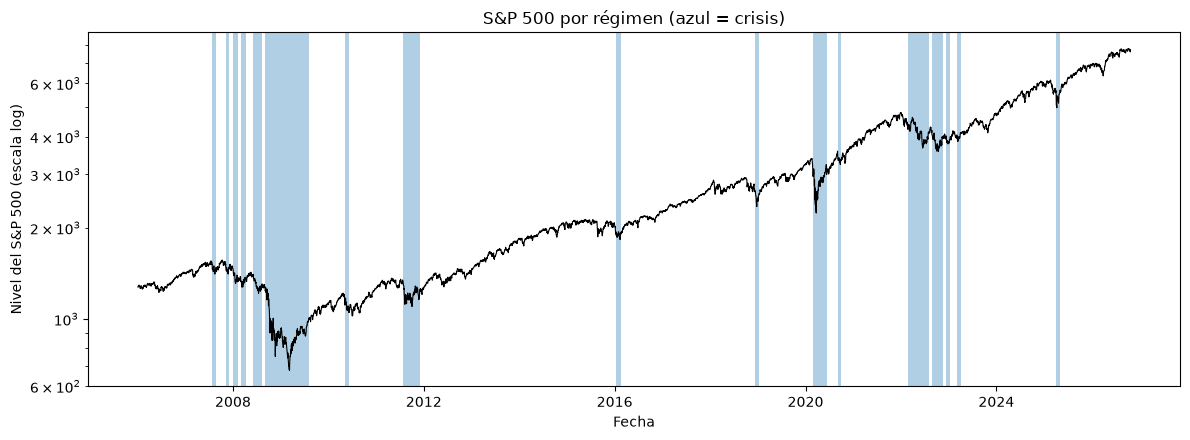

In [27]:
sp = datos.prices[config.MARKET_TICKER].reindex(reg.states.index)
figures.plot_regimes(sp, reg.states)
plt.show()

**El gráfico.** S&P 500 en escala logarítmica; **azul = crisis, blanco = calma**. Las bandas azules coinciden con los episodios que reconocemos: la crisis financiera de 2008-2009 (la banda más larga), la deuda europea de 2010-2011,
el COVID de 2020, la estanflación de 2022 y los aranceles de 2025. Se ve que las crisis son **raras pero concentradas**, y que la banda de 2022 aparece partida en varios episodios (el mercado «respiró» entre subidas de tipos).

In [28]:
epi = reg.episodes.copy()
epi["caida_sp500"] = epi["caida_sp500"].map(pct)
epi["pico_vix"] = epi["pico_vix"].round(1)
display(epi)
peor = reg.episodes.loc[reg.episodes["caida_sp500"].idxmin()]
largo = reg.episodes.loc[reg.episodes["dias"].idxmax()]
display(Markdown(f"**Por qué cada episodio es crisis.** La tabla combina tres evidencias independientes del HMM: duración, caída máxima del S&P 500 y pico del VIX, y una narrativa económica "
                 f"(etiqueta histórica por solapamiento de fechas; lo que no solapa queda «sin etiqueta»). El más profundo es el que empieza el {peor['inicio']} (caída del {pct(-peor['caida_sp500'])}, VIX {peor['pico_vix']:.0f}); "
                 f"el más largo dura {largo['dias']} días (desde {largo['inicio']})."))
display(reg.sensitivity.rename(columns={"pct_crisis": "% días en crisis"}))
display(Markdown("**Sensibilidad a la duración mínima (10/15/20 días).** Cambia el número de episodios (los cortos se absorben o se funden) pero casi no cambia el % de días en crisis: la conclusión sobre *cuánto tiempo* pasa el mercado en crisis es robusta."))

,inicio,fin,dias,caida_sp500,pico_vix,narrativa
0,2007-07-24,2007-08-20,20,"-8,7 %",30.8000,"Crisis financiera global: hipotecas subprime, ..."
1,2007-11-07,2007-11-28,15,"-7,4 %",31.1000,"Crisis financiera global: hipotecas subprime, ..."
2,2007-12-31,2008-02-05,25,"-11,4 %",31.0000,"Crisis financiera global: hipotecas subprime, ..."
3,2008-03-06,2008-04-08,23,"-4,5 %",32.2000,"Crisis financiera global: hipotecas subprime, ..."
4,2008-06-05,2008-08-08,46,"-11,8 %",28.5000,"Crisis financiera global: hipotecas subprime, ..."
5,2008-09-04,2009-08-03,230,"-46,9 %",80.9000,"Crisis financiera global: hipotecas subprime, ..."
6,2010-05-04,2010-06-10,27,"-12,6 %",45.8000,Crisis de deuda soberana europea y «flash crash»
7,2011-07-29,2011-11-30,87,"-15,5 %",48.0000,Rebaja de rating de EE. UU. y contagio de la c...
8,2016-01-11,2016-02-17,26,"-4,8 %",28.1000,"Devaluación del yuan, caída del petróleo y mie..."
9,2018-12-14,2019-01-08,16,"-11,3 %",36.1000,Venta masiva del 4T 2018: Fed restrictiva y gu...


**Por qué cada episodio es crisis.** La tabla combina tres evidencias independientes del HMM: duración, caída máxima del S&P 500 y pico del VIX, y una narrativa económica (etiqueta histórica por solapamiento de fechas; lo que no solapa queda «sin etiqueta»). El más profundo es el que empieza el 2008-09-04 (caída del 46,9 %, VIX 81); el más largo dura 230 días (desde 2008-09-04).

,% días en crisis,n_cambios,n_episodios_crisis
min_dias,,,
10,0.1712,48.0000,24.0000
15,0.1611,34.0000,17.0000
20,0.1607,22.0000,11.0000


**Sensibilidad a la duración mínima (10/15/20 días).** Cambia el número de episodios (los cortos se absorben o se funden) pero casi no cambia el % de días en crisis: la conclusión sobre *cuánto tiempo* pasa el mercado en crisis es robusta.

## 3. Distribuciones marginales condicionales
Para cada activo y estado se calculan **media, volatilidad, asimetría y curtosis**, y se ajustan dos candidatas: **Normal** y **Student-t** (colas gruesas), elegidas por **BIC** (que penaliza el parámetro extra de la t;
también se guarda el AIC). Se limitan los grados de libertad a ≥ 3 (D-26): por debajo de 3 el ajuste está dominado por muchos retornos cercanos a cero y exagera las colas, lo que en 10.000×126 días produciría caídas diarias absurdas.

In [29]:
mar = run_marginals(datos.prices, datos.rates, reg.states, trace)
vistos = ["AAPL", "BAC", "GLD", "GME", "HYG", "JPM", "UST10Y", "UST2Y", "XOM"]
display(mar.moments.loc[vistos].rename(columns={"kurt_exceso": "curtosis (exceso)", "vol_anual": "vol. anual"}))
display(Markdown("**Cómo leer la tabla.** En crisis la volatilidad sube en casi todos los activos (los bancos BAC y JPM se multiplican por 3-4; GLD y los bonos por 1,5-2); las excepciones son ENPH y GME, que ya eran extremadamente volátiles en calma. La curtosis (exceso sobre una Normal) es alta **en ambos regímenes**: los retornos diarios tienen colas gruesas siempre, no solo en las crisis."))
n_t = sum(m.family == "t" for m in mar.marginals.values())
suelo = [i for i in mar.fit_table.index[mar.fit_table["df_t"] <= marginals.DF_BOUNDS[0] + 1e-6]]
normales = [i for i in mar.fit_table.index[mar.fit_table["elegida"] == "normal"]]
display(Markdown(f"**Normal frente a t.** La t gana en **{n_t} de {len(mar.marginals)}** ajustes (18 activos × 2 estados), también en calma. "
                 f"En {len(suelo)} casos los grados de libertad quedan en el suelo de 3 ({', '.join(f'{a} en {e}' for a, e in suelo)}): "
                 "colas muy pesadas que el simulador mantiene, pero acotadas."
                 + (f" La Normal gana en: {', '.join(f'{a} en {e}' for a, e in normales)}." if normales else "")))

n   media    vol  vol. anual    skew  curtosis (exceso)
activo estado                                                                 
AAPL   calma  4,391.0000  0.0015 0.0167      0.2644  0.1745             3.6716
       crisis   843.0000 -0.0007 0.0317      0.5035  0.0174             3.1067
BAC    calma  4,391.0000  0.0008 0.0167      0.2657  0.1535             3.2150
       crisis   843.0000 -0.0008 0.0613      0.9728  0.6240             6.1800
GLD    calma  4,391.0000  0.0004 0.0106      0.1690 -0.6843             5.8715
       crisis   843.0000  0.0006 0.0159      0.2530  0.2996             4.4083
GME    calma  4,391.0000  0.0019 0.0550      0.8731  7.5324           160.3323
       crisis   843.0000  0.0010 0.0549      0.8708  1.3327             5.9814
HYG    calma  4,391.0000  0.0004 0.0024      0.0385 -0.0095             4.9807
       crisis   843.0000 -0.0001 0.0078      0.1244 -0.5057             7.3684
JPM    calma  4,391.0000  0.0009 0.0145      0.2304  0.1078             4.9523
       crisis   843.0000  0.0002 0.0462      0.7338  0.7031             4.8734
UST10Y calma  4,391.0000  0.0001 0.0042      0.0663 -0.0929             0.7537
       crisis   843.0000  0.0004 0.0075      0.1184  0.2821             1.7461
UST2Y  calma  4,391.0000  0.0001 0.0008      0.0130  0.2959             4.4128
       crisis   843.0000  0.0002 0.0017      0.0262  0.4657             5.6767
XOM    calma  4,391.0000  0.0006 0.0131      0.2086  0.2422             3.5141
       crisis   843.0000 -0.0002 0.0292      0.4628  0.1616             4.3025

**Cómo leer la tabla.** En crisis la volatilidad sube en casi todos los activos (los bancos BAC y JPM se multiplican por 3-4; GLD y los bonos por 1,5-2); las excepciones son ENPH y GME, que ya eran extremadamente volátiles en calma. La curtosis (exceso sobre una Normal) es alta **en ambos regímenes**: los retornos diarios tienen colas gruesas siempre, no solo en las crisis.

**Normal frente a t.** La t gana en **35 de 36** ajustes (18 activos × 2 estados), también en calma. En 9 casos los grados de libertad quedan en el suelo de 3 (BAC en crisis, GME en calma, JNJ en crisis, JPM en crisis, HYG en calma, HYG en crisis, UST10Y en calma, UST2Y en calma, UST2Y en crisis): colas muy pesadas que el simulador mantiene, pero acotadas. La Normal gana en: UST10Y en calma.

In [30]:
r = mar.refuge
display(Markdown(
    f"### Respuestas de la práctica\n"
    f"* **¿Cuánto sube la volatilidad de HYG de calma a crisis?** De {pct(r['hyg_vol_calma'], 2)} a {pct(r['hyg_vol_crisis'], 2)} diaria: **×{r['hyg_ratio_vol']:.1f}**. "
    f"El crédito de alto rendimiento se comporta como un activo de riesgo (primo de liquidez + riesgo de impago), no como un bono refugio.\n"
    f"* **¿Sigue siendo GLD un refugio?** En crisis el oro rinde de media {pct(r['gld_media_crisis'], 3)} al día frente a {pct(r['sp500_media_crisis'], 3)} del S&P 500, "
    f"su correlación con el S&P 500 es {r['gld_corr_sp500_crisis']:.2f} (en calma {r['gld_corr_sp500_calma']:.2f}) y sube en el {pct(r['gld_dias_positivos_crisis'])} de los días de crisis. "
    f"**Sigue siendo un diversificador** (no cae con las acciones), pero su volatilidad también sube ×{r['gld_ratio_vol']:.1f}: refugio relativo, no inmunidad."))

### Respuestas de la práctica
* **¿Cuánto sube la volatilidad de HYG de calma a crisis?** De 0,24 % a 0,78 % diaria: **×3.2**. El crédito de alto rendimiento se comporta como un activo de riesgo (primo de liquidez + riesgo de impago), no como un bono refugio.
* **¿Sigue siendo GLD un refugio?** En crisis el oro rinde de media 0,058 % al día frente a -0,076 % del S&P 500, su correlación con el S&P 500 es 0.03 (en calma 0.11) y sube en el 51,5 % de los días de crisis. **Sigue siendo un diversificador** (no cae con las acciones), pero su volatilidad también sube ×1.5: refugio relativo, no inmunidad.

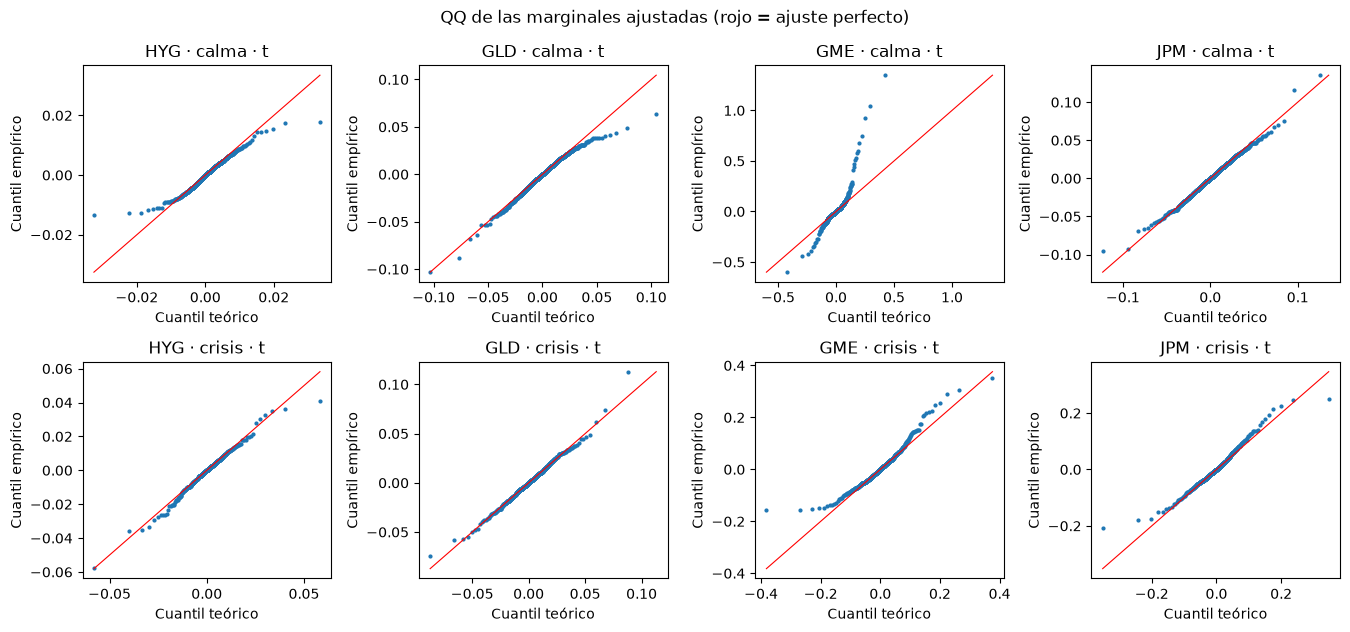

In [31]:
figures.plot_qq(mar.returns, reg.states, mar.marginals, ["HYG", "GLD", "GME", "JPM"])
plt.show()

**El gráfico (QQ).** Cada punto compara un cuantil de los datos (eje vertical) con el de la distribución ajustada (eje horizontal); la recta roja es el ajuste perfecto. Los puntos pegados a la recta indican buen ajuste.
Las **colas** (extremos) son lo que importa para el riesgo: en GLD y JPM la t sigue bien los datos incluso en los extremos; en **HYG en calma** la t con 3 g.l. sobreestima las colas (los puntos se aplanan en los extremos) y en **GME** los datos tienen una cola derecha mucho más extrema que cualquier ajuste (enero de 2021). Es un ajuste conservador en las pérdidas.

## 4. Dependencia: correlaciones y cópulas por estado
**Cópula (teorema de Sklar).** Separa las marginales de la **estructura de dependencia**: cada activo se transforma a una uniforme (pseudo-observación por rangos) y la cópula modela cómo se mueven juntas.
La Gauss no tiene dependencia en las colas; la **t sí** (simétrica): captura que las caídas extremas tienden a coincidir. Se estiman en la **ventana común** (días con los 18 activos, desde que cotiza ENPH, abril de 2012),
por lo que la crisis de 2008 queda fuera de la estimación de dependencia (el escenario E2 la recalibra con una proxy). Las correlaciones de la t se estiman con la tau de Kendall (robusta a outliers) y los grados de libertad por máxima verosimilitud.

Ventana común: **3662** días (3292 en calma y 370 en crisis).

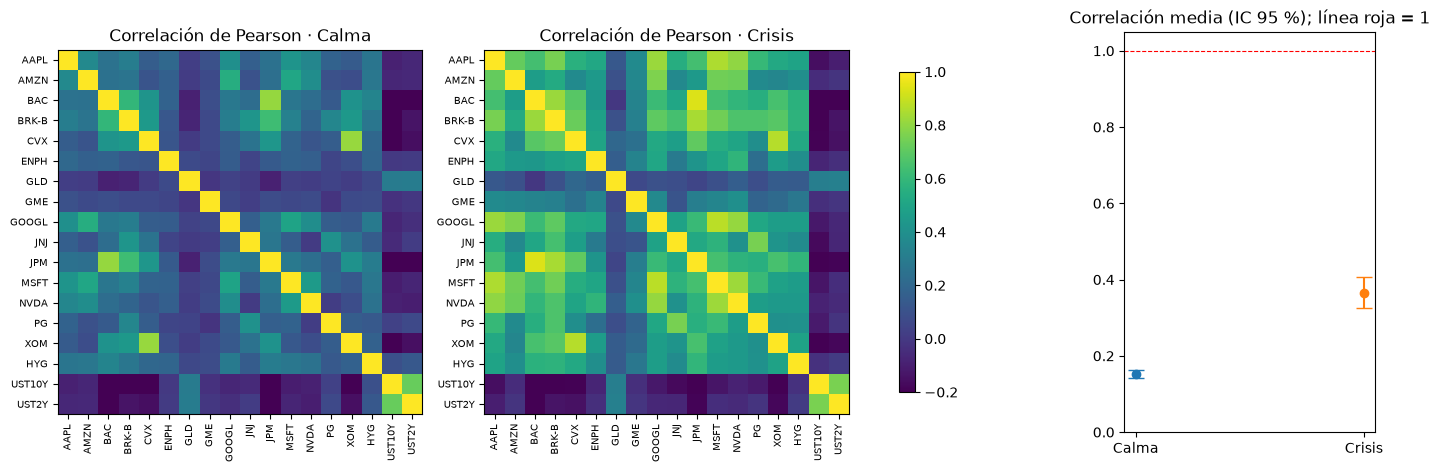

**Contraste «en crisis las correlaciones tienden a 1».** La correlación media entre pares pasa de **0.15** (IC 95 % 0.14–0.16) en calma a **0.36** (IC 95 % 0.32–0.41) en crisis; la diferencia es 0.21 (IC 95 % 0.17–0.25; 88 % de los pares suben). **Suben mucho y de forma significativa, pero no tienden a 1** en esta cartera diversificada: los bonos del Tesoro y el oro diluyen la media (son los cuadrados oscuros del mapa). Entre algunos pares de acciones (bancos entre sí, grandes tecnológicas entre sí) sí superan 0,8 en crisis.

In [32]:
cop = run_copulas(mar.returns, reg.states, datos.prices, datos.rates, trace)
c = cop.summary
display(Markdown(f"Ventana común: **{c['n_ventana']}** días ({c['n_calma']} en calma y {c['n_crisis']} en crisis)."))
figures.plot_correlaciones(cop.corr[0], cop.corr[1], cop.names, c["bootstrap"])
plt.show()
b = c["bootstrap"]
display(Markdown(
    f"**Contraste «en crisis las correlaciones tienden a 1».** La correlación media entre pares pasa de **{b[0]['media']:.2f}** (IC 95 % {b[0]['ic_inf']:.2f}–{b[0]['ic_sup']:.2f}) en calma a **{b[1]['media']:.2f}** "
    f"(IC 95 % {b[1]['ic_inf']:.2f}–{b[1]['ic_sup']:.2f}) en crisis; la diferencia es {b['dif']['diferencia']:.2f} (IC 95 % {b['dif']['ic_inf']:.2f}–{b['dif']['ic_sup']:.2f}; "
    f"{pct(c['perfil_estados']['pct_pares_corr_sube'], 0)} de los pares suben). **Suben mucho y de forma significativa, pero no tienden a 1** en esta cartera diversificada: "
    "los bonos del Tesoro y el oro diluyen la media (son los cuadrados oscuros del mapa). Entre algunos pares de acciones (bancos entre sí, grandes tecnológicas entre sí) sí superan 0,8 en crisis."))

**El gráfico.** Izquierda y centro: mapas de calor de la correlación de Pearson (amarillo = alta, morado = negativa). El de crisis es claramente más claro: todo el bloque de acciones se «enciende» a la vez; los bonos (últimas dos filas) siguen en tonos oscuros: negativos frente a las acciones. Derecha: correlación media con su intervalo del 95 % (bootstrap de días); la línea roja es el valor 1 que habría si «todo cayera junto».

In [33]:
display(cop.table[["loglik", "aic", "bic", "df", "lambda_L_ajustada", "lambda_L_empirica"]])
display(Markdown(
    f"**Elección de la cópula (D-07).** La t gana por AIC y BIC en ambos estados (g.l. {cop.fits[0]['t'].df:.1f} en calma y {cop.fits[1]['t'].df:.1f} en crisis; en calma es casi gaussiana). "
    "La *dependencia de cola inferior* λ_L (probabilidad de que dos activos estén a la vez en su peor 5 % de días) es más fiel con la t que con la Gauss en ambos estados: "
    "la Gauss subestima el riesgo conjunto. Clayton (un solo parámetro) queda descartada por rígida en 18 dimensiones."))

loglik          aic          bic      df  lambda_L_ajustada  lambda_L_empirica
estado familia                                                                                    
calma  gauss   11,621.1032 -22,936.2064 -22,003.0210     NaN             0.1130             0.1682
       t       12,431.6399 -24,555.2798 -23,615.9952 14.1960             0.1416             0.1682
crisis gauss    2,935.7340  -5,565.4680  -4,966.7021     NaN             0.2077             0.2689
       t        3,051.1353  -5,794.2707  -5,191.5912 10.6895             0.2418             0.2689

**Elección de la cópula (D-07).** La t gana por AIC y BIC en ambos estados (g.l. 14.2 en calma y 10.7 en crisis; en calma es casi gaussiana). La *dependencia de cola inferior* λ_L (probabilidad de que dos activos estén a la vez en su peor 5 % de días) es más fiel con la t que con la Gauss en ambos estados: la Gauss subestima el riesgo conjunto. Clayton (un solo parámetro) queda descartada por rígida en 18 dimensiones.

### Pregunta intermedia: ¿qué distingue realmente un estado del otro?

In [34]:
p = c["perfil_estados"]
d = c["descomposicion_riesgo"]
evidencia = pd.DataFrame({
    "calma": [p["vix_medio_calma"], p["oas_medio_calma"], p["corr_media_calma"], p["lambda_L_calma"], d["vol_calma"]],
    "crisis": [p["vix_medio_crisis"], p["oas_medio_crisis"], p["corr_media_crisis"], p["lambda_L_crisis"], d["vol_crisis"]],
}, index=["VIX medio", "OAS high yield medio (pp)", "Correlación media", "Dependencia de cola λ_L (5 %)", "Vol. diaria de cartera equiponderada"])
display(evidencia)
sube_vol = (d["vol_solo_vols_crisis"] - d["vol_calma"]) / (d["vol_crisis"] - d["vol_calma"])
sube_corr = (d["vol_solo_corr_crisis"] - d["vol_calma"]) / (d["vol_crisis"] - d["vol_calma"])
display(Markdown(
    f"**Respuesta.** Los dos estados se distinguen en cuatro cosas medibles: **(1) volatilidad** (mediana por activo ×{p['mediana_ratio_vol']:.1f}); **(2) correlación** ({p['corr_media_calma']:.2f} → {p['corr_media_crisis']:.2f}); "
    f"**(3) dependencia de cola** ({p['lambda_L_calma']:.2f} → {p['lambda_L_crisis']:.2f}); y **(4) variables de mercado** (VIX {p['vix_medio_calma']:.0f} → {p['vix_medio_crisis']:.0f}; OAS {p['oas_medio_calma']:.1f} → {p['oas_medio_crisis']:.1f} pp). "
    f"¿Qué pesa más? Si en una cartera equiponderada se cambian solo las volatilidades a las de crisis, el riesgo sube {pct(sube_vol, 0)} del salto total; si se cambian solo las correlaciones, {pct(sube_corr, 0)}; el resto es **interacción** (volatilidades y correlaciones altas se refuerzan). "
    "**Interpretación económica:** una crisis es un régimen en el que los inversores dejan de diferenciar entre activos (la liquidez y el miedo dominan sobre los fundamentales), por eso sube la dependencia conjunta, y en el que la incertidumbre se paga (más VIX y más diferencial de crédito)."))

,calma,crisis
VIX medio,16.3902,29.5300
OAS high yield medio (pp),4.1267,5.4255
Correlación media,0.1514,0.3639
Dependencia de cola λ_L (5 %),0.1682,0.2689
Vol. diaria de cartera equiponderada,0.0082,0.0200


**Respuesta.** Los dos estados se distinguen en cuatro cosas medibles: **(1) volatilidad** (mediana por activo ×2.0); **(2) correlación** (0.15 → 0.36); **(3) dependencia de cola** (0.17 → 0.27); y **(4) variables de mercado** (VIX 16 → 30; OAS 4.1 → 5.4 pp). ¿Qué pesa más? Si en una cartera equiponderada se cambian solo las volatilidades a las de crisis, el riesgo sube 48 % del salto total; si se cambian solo las correlaciones, 31 %; el resto es **interacción** (volatilidades y correlaciones altas se refuerzan). **Interpretación económica:** una crisis es un régimen en el que los inversores dejan de diferenciar entre activos (la liquidez y el miedo dominan sobre los fundamentales), por eso sube la dependencia conjunta, y en el que la incertidumbre se paga (más VIX y más diferencial de crédito).

## 5. Simulador Monte Carlo y validación
**Mecánica (por trayectoria y día).** (1) El estado inicial se toma de la **distribución estacionaria** de la cadena (D-08; sin información de coyuntura, el mercado puede estar en cualquier régimen con su frecuencia de largo plazo); (2) el estado de cada día se sortea con la matriz de transición
`S_t ~ P[S_{t-1}, ·]`; (3) se genera un vector de uniformes `U_t` de la **cópula del estado activo**; (4) cada activo se obtiene con la inversa de su marginal del estado: `R_{t,i} = F⁻¹_{i,S_t}(U_{t,i})`. La cartera es **equiponderada sin rebalanceo** (*buy & hold*):
`W_t = (1/N)·Σ_i Π_{s≤t}(1+r_{i,s})`. Los retornos diarios simulados se topan en ±2× el extremo histórico de cada activo (afecta a una fracción mínima; D-31).

**Validación (D-09).** Se compara con **ventanas móviles reales de 126 días** (solapadas, con la riqueza reiniciada a 1 en cada una) y, para regímenes, con toda la serie 2006-2026.

### A. Cartera: abanico simulado y retornos diarios

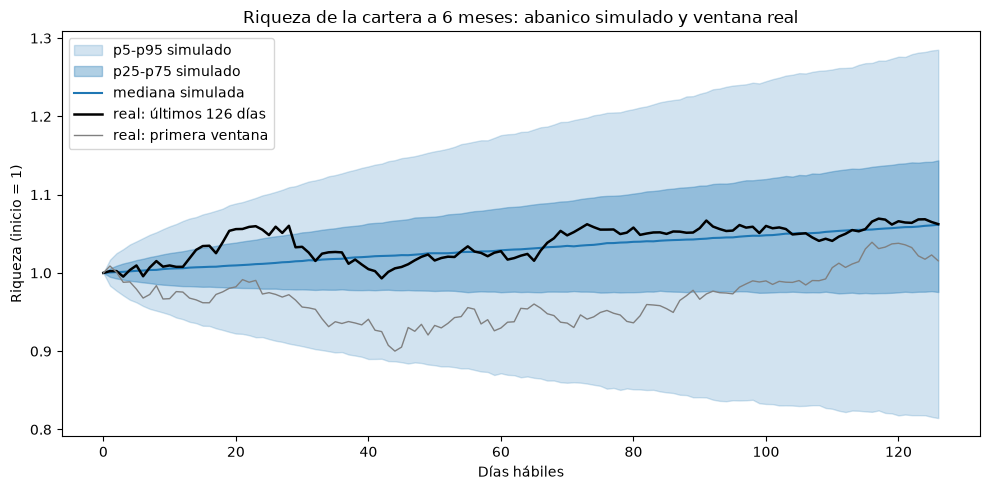

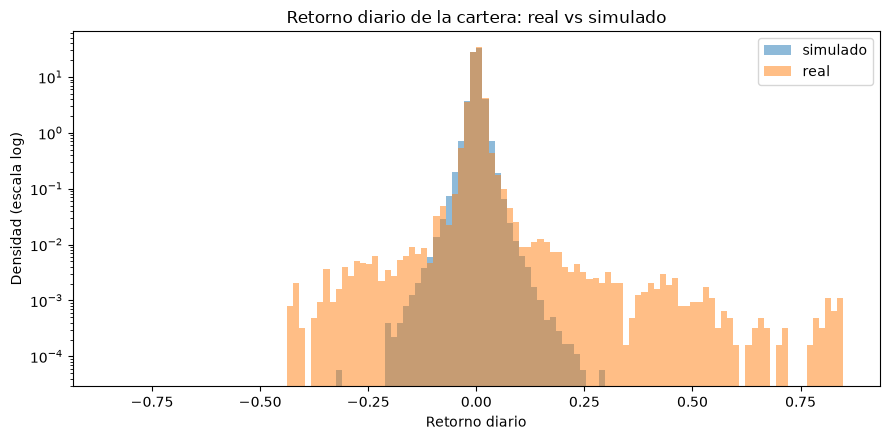

,real,simulado
percentil,,
0.1000,-0.1339,-0.0671
1.0000,-0.0296,-0.0330
5.0000,-0.0157,-0.0165
25.0000,-0.0042,-0.0048
50.0000,0.0010,0.0006
75.0000,0.0061,0.0059
95.0000,0.0162,0.0168
99.0000,0.0351,0.0322
99.9000,0.1716,0.0651


In [35]:
sim = run_simulation(mar, cop, reg.states, trace)
t = sim.tables
display(Markdown("### A. Cartera: abanico simulado y retornos diarios"))
figures.plot_abanico(sim.fan, sim.real_wealth)
plt.show()
figures.plot_hist_retornos(sim.real_daily, sim.sim_daily)
plt.show()
display(t["percentiles_diarios"])

**Los gráficos.** *Abanico*: la franja azul clara es el rango p5-p95 de la riqueza simulada de la cartera, la oscura p25-p75 y la línea azul la mediana; las líneas negra y gris son dos ventanas **reales** de 126 días (las últimas y las primeras). La realidad cae dentro del abanico: el modelo no «se sale del mapa».
*Histograma* (escala logarítmica, para ver las colas): el simulado reproduce el cuerpo de la distribución diaria real; en las colas extremas el real tiene días peores y mejores por GME (enero de 2021), que el tope de ±2× del simulador no replica por diseño.

In [36]:
display(Markdown("### B. Regímenes: real frente a simulado"))
display(t["regimenes"])
display(Markdown("(*Real* = ventanas móviles de 126 días de los estados duros 2006-2026; *teórico* = valor de la cadena. Las duraciones medias de las ventanas están truncadas por el horizonte de 126 días, por eso son menores que las esperadas.)"))

### B. Regímenes: real frente a simulado

,real_ventanas,simulado,teorico_cadena
pct_dias_crisis,0.1650,0.1612,0.1611
cambios_por_ventana,0.8319,0.8120,NaN
duracion_media_calma,84.1051,85.0286,258.2353
duracion_media_crisis,35.7877,35.6933,49.5882


(*Real* = ventanas móviles de 126 días de los estados duros 2006-2026; *teórico* = valor de la cadena. Las duraciones medias de las ventanas están truncadas por el horizonte de 126 días, por eso son menores que las esperadas.)

In [37]:
display(Markdown("### C. Riesgo: volatilidad, VaR 99 %, ES 99 % y drawdown (pérdidas en positivo)"))
display(t["riesgo"])
display(Markdown("**Sensibilidad quitando GME** (el *short squeeze* de enero de 2021 domina las colas de la cartera real *buy & hold*, porque su peso se disparaba antes de desplomarse):"))
display(t["riesgo_sin_GME"])
cob = sim.summary["cobertura"]
rg, rk = t["riesgo"], t["riesgo_sin_GME"]
display(Markdown(
    f"**Lectura.** *Regímenes*: el simulador reproduce el % de días en crisis, los cambios y las duraciones. *Riesgo*: con GME, la volatilidad real ({pct(rg.loc['vol_anualizada', 'real'])}) supera a la simulada ({pct(rg.loc['vol_anualizada', 'simulado'])}) por el *squeeze*; "
    f"sin GME es la simulada la que es algo mayor ({pct(rk.loc['vol_anualizada', 'simulado'])} frente a {pct(rk.loc['vol_anualizada', 'real'])}): **el modelo es conservador**. El VaR 99 % diario sin GME es {pct(rk.loc['var99_diario', 'simulado'], 2)} simulado frente a {pct(rk.loc['var99_diario', 'real'], 2)} real. "
    f"A 6 meses el VaR 99 % simulado ({pct(rg.loc['var99_6m', 'simulado'])}) está muy por encima del histórico ({pct(rg.loc['var99_6m', 'real'])}): el histórico a 6 meses 2012-2026 se apoya en unas {len(sim.real_wealth) / 126:.0f} ventanas independientes y **no contiene una crisis sostenida tipo 2008**; no es un buen árbitro del percentil 99. "
    f"El {pct(cob['cobertura_p5_p95_real'], 0)} de las ventanas reales cae dentro de la banda p5-p95 simulada (el 90 % sería lo ideal). "
    f"Fíjate también en el **VaR/ES paramétrico normal** (sin GME, con la volatilidad real): el VaR normal diario es {pct(rk.loc['var99_normal_diario', 'real'], 2)} frente a {pct(rk.loc['var99_diario', 'real'], 2)} histórico y el ES normal {pct(rk.loc['es99_normal_diario', 'real'], 2)} frente a {pct(rk.loc['es99_diario', 'real'], 2)}: "
    "la hipótesis de normalidad subestima la pérdida extrema de las colas gruesas, sobre todo en el ES. Es el motivo de usar ES y no solo VaR (el VaR no es subaditivo y ignora la severidad más allá del umbral). "
    "(Con GME la volatilidad real se infla y el VaR normal pasa a *sobrestimar*: por eso la comparación limpia es la de la tabla sin GME.)"))

### C. Riesgo: volatilidad, VaR 99 %, ES 99 % y drawdown (pérdidas en positivo)

,real,simulado
vol_diaria,0.0186,0.0116
vol_anualizada,0.2958,0.1837
var99_diario,0.0296,0.0330
es99_diario,0.0651,0.0474
var99_normal_diario,0.0423,0.0265
es99_normal_diario,0.0486,0.0304
var99_6m,0.1067,0.2936
es99_6m,0.1289,0.3449
retorno_6m_mediano,0.0930,0.0615
mdd_medio_6m,0.1014,0.1150


**Sensibilidad quitando GME** (el *short squeeze* de enero de 2021 domina las colas de la cartera real *buy & hold*, porque su peso se disparaba antes de desplomarse):

,real,simulado
vol_diaria,0.0095,0.0112
vol_anualizada,0.1512,0.1781
var99_diario,0.0261,0.0320
es99_diario,0.0370,0.0461
var99_normal_diario,0.0214,0.0256
es99_normal_diario,0.0246,0.0294
var99_6m,0.1024,0.2768
es99_6m,0.1203,0.3305
retorno_6m_mediano,0.0958,0.0658
mdd_medio_6m,0.0812,0.1097


**Lectura.** *Regímenes*: el simulador reproduce el % de días en crisis, los cambios y las duraciones. *Riesgo*: con GME, la volatilidad real (29,6 %) supera a la simulada (18,4 %) por el *squeeze*; sin GME es la simulada la que es algo mayor (17,8 % frente a 15,1 %): **el modelo es conservador**. El VaR 99 % diario sin GME es 3,20 % simulado frente a 2,61 % real. A 6 meses el VaR 99 % simulado (29,4 %) está muy por encima del histórico (10,7 %): el histórico a 6 meses 2012-2026 se apoya en unas 28 ventanas independientes y **no contiene una crisis sostenida tipo 2008**; no es un buen árbitro del percentil 99. El 94 % de las ventanas reales cae dentro de la banda p5-p95 simulada (el 90 % sería lo ideal). Fíjate también en el **VaR/ES paramétrico normal** (sin GME, con la volatilidad real): el VaR normal diario es 2,14 % frente a 2,61 % histórico y el ES normal 2,46 % frente a 3,70 %: la hipótesis de normalidad subestima la pérdida extrema de las colas gruesas, sobre todo en el ES. Es el motivo de usar ES y no solo VaR (el VaR no es subaditivo y ignora la severidad más allá del umbral). (Con GME la volatilidad real se infla y el VaR normal pasa a *sobrestimar*: por eso la comparación limpia es la de la tabla sin GME.)

In [38]:
display(Markdown("### D. Comportamiento en estrés (R-VAL-04): ¿suben la volatilidad y los co-movimientos extremos?"))
display(t["estres"])
display(Markdown("En ambos regímenes la volatilidad mediana por activo, la correlación media y la dependencia de cola simuladas están cerca de las reales; la curtosis simulada es mayor (las colas de la t con 3-4 g.l. son más pesadas que las observadas, otra señal de conservadurismo). "
                 "En crisis suben a la vez la volatilidad, la correlación y la dependencia de cola, como en los datos."))

### D. Comportamiento en estrés (R-VAL-04): ¿suben la volatilidad y los co-movimientos extremos?

n  vol_mediana_activos  corr_media  lambda_L_5pct  curtosis_exceso_mediana
estado fuente                                                                                        
calma  real       3,292.0000               0.0137      0.1514         0.1682                   5.0116
       simulado 100,000.0000               0.0139      0.1770         0.1403                  13.0051
crisis real         370.0000               0.0296      0.3639         0.2689                   3.8555
       simulado 100,000.0000               0.0291      0.3544         0.2448                   9.2219

En ambos regímenes la volatilidad mediana por activo, la correlación media y la dependencia de cola simuladas están cerca de las reales; la curtosis simulada es mayor (las colas de la t con 3-4 g.l. son más pesadas que las observadas, otra señal de conservadurismo). En crisis suben a la vez la volatilidad, la correlación y la dependencia de cola, como en los datos.

## 6. Escenarios de estrés
En los tres escenarios **solo se sustituye el estado de crisis** (la calma y la cadena de Markov no cambian) y las simulaciones **arrancan en crisis**. Se reportan VaR 99 % y ES 99 % **diario, a 1 mes (21 días) y a 6 meses (126 días)**, siempre como pérdida positiva sobre el capital; ES = media de las pérdidas iguales o superiores al VaR.

* **E1 · Estanflación 2022** (enero-diciembre de 2022): acciones y bonos cayeron a la vez porque la inflación obligó a subir tipos; se recalibran marginales y cópula con los 187 días de crisis de 2022.
* **E2 · Crisis de crédito 2008** (septiembre de 2008 a marzo de 2009): ENPH no cotizaba, así que se usa una **proxy** (ENPH = α + β·S&P 500 + ruido idiosincrático por estado; β ≈ 1,6 estimada en 2012-2026) y se hace análisis de sensibilidad. Es un supuesto fuerte: la «proxy» es una cartera sintética.
* **E3 · Pánico de liquidez crediticia** (escenario propio, D-11): en un pánico de liquidez los inversores venden lo que *pueden* vender, no lo que *quieren*; los diferenciales de crédito se abren y **la diversificación falla**. Se modela con volatilidad ×1,5 (exacta), un grado de libertad menos en las marginales,
  cópula t con 3 g.l. y correlaciones `R' = 0,7·R + 0,3·J` (J = matriz de unos). Es el mecanismo que no captura ningún dato histórico concreto: 2022 fue un problema de tipos e inflación y 2008 de crédito hipotecario; aquí la dependencia conjunta de cola es el protagonista.

,Base,E1,E2,E3
Volatilidad anual,0.1837,0.1914,0.3418,0.3718
VaR 99 % diario,0.0330,0.0327,0.0657,0.0707
ES 99 % diario,0.0474,0.0408,0.0827,0.1039
VaR 99 % 1 mes,0.1613,0.1528,0.2871,0.3189
ES 99 % 1 mes,0.2002,0.1743,0.3151,0.3604
VaR 99 % 6 meses,0.2936,0.2616,0.4960,0.5094
ES 99 % 6 meses,0.3449,0.3003,0.5346,0.5580
Max. drawdown medio 6m,0.1150,0.1311,0.2398,0.2364
Max. drawdown p95 6m,0.2719,0.2481,0.4692,0.4724
Retorno mediano 6m,0.0615,0.0290,-0.0315,-0.0042


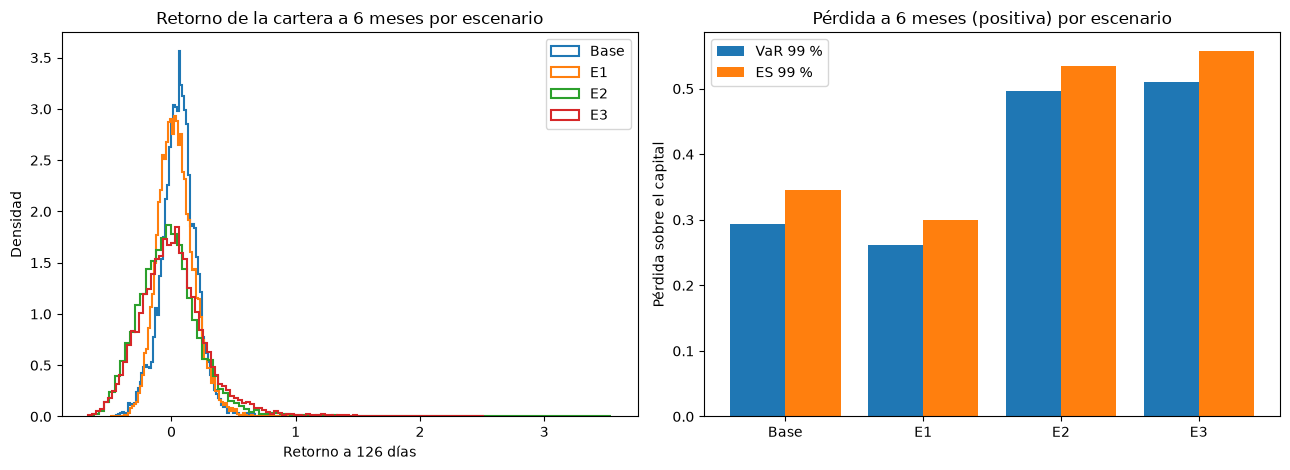

In [39]:
esc = run_scenarios(datos.prices, mar, cop, reg.states, sim, trace)
etiquetas = {"vol_anualizada": "Volatilidad anual", "var99_diario": "VaR 99 % diario", "es99_diario": "ES 99 % diario",
             "var99_1m": "VaR 99 % 1 mes", "es99_1m": "ES 99 % 1 mes", "var99_6m": "VaR 99 % 6 meses", "es99_6m": "ES 99 % 6 meses",
             "mdd_medio_6m": "Max. drawdown medio 6m", "mdd_p95_6m": "Max. drawdown p95 6m",
             "retorno_mediano_6m": "Retorno mediano 6m", "prob_perdida_20pct_6m": "Prob. pérdida > 20 % a 6m"}
display(esc.comparativa.rename(index=etiquetas))
terminales = {"Base": sim.wealth[:, -1] - 1.0, **{k: v["w"][:, -1] - 1.0 for k, v in esc.outcomes.items()}}
figures.plot_escenarios(terminales, esc.comparativa)
plt.show()

**El gráfico.** Izquierda: distribución del retorno de la cartera a 6 meses en cada escenario; cuanto más desplazada a la izquierda y más ancha, peor. E1 se parece a la base (la estanflación fue una sangría lenta, no un desplome);
E2 y E3 desplazan y ensanchan la distribución. Derecha: VaR y ES al 99 % a 6 meses; el ES siempre supera al VaR porque promedia todo lo que pasa más allá del umbral.

In [40]:
display(Markdown("### Calibración y validación contra la ventana real"))
display(esc.calibracion)
display(esc.validacion_ventana.rename(columns={"retorno_real": "retorno real 6m", "percentil_retorno_real": "percentil en el escenario"}))
cb = esc.summary["corr_bonos_acciones_base"]
cm = esc.comparativa
display(Markdown(
    f"**Qué enseña cada escenario.** (1) **E1**: el ES 99 % a 6 meses ({pct(cm.loc['es99_6m', 'E1'])}) es *menor* que el de la crisis base ({pct(cm.loc['es99_6m', 'Base'])}) porque 2022 fue una sangría lenta (cópula casi gaussiana) y la crisis base incluye el COVID; "
    f"lo que cambia es el **signo de la cobertura**: la correlación media bono-acción es {esc.calibracion.loc[0, 'corr_bonos_acciones']:+.2f} en 2022, {cb['crisis']:+.2f} en la crisis base y {esc.calibracion.loc[1, 'corr_bonos_acciones']:+.2f} en 2008. "
    f"Un VaR de cola no capta que, en 2022, la renta fija dejó de proteger. (2) **E2** es el más duro de los dos escenarios históricos (volatilidad {pct(cm.loc['vol_anualizada', 'E2'])} anual) y arrastra una probabilidad de perder más del 20 % a 6 meses del {pct(cm.loc['prob_perdida_20pct_6m', 'E2'], 0)}. "
    f"(3) **E3** tiene un VaR/ES similar a E2 ({pct(cm.loc['es99_6m', 'E3'])} frente a {pct(cm.loc['es99_6m', 'E2'])}) pero por otra vía: la dependencia conjunta de cola sube (λ_L {esc.perfil_crisis.loc['E3', 'lambda_L_5pct']:.2f} frente a {esc.perfil_crisis.loc['E1', 'lambda_L_5pct']:.2f} en E1). "
    f"**Validación**: las ventanas reales de E1 y E2 caen en los percentiles {pct(esc.validacion_ventana.loc['E1', 'percentil_retorno_real'], 0)} y {pct(esc.validacion_ventana.loc['E2', 'percentil_retorno_real'], 0)} de su escenario: dentro del rango, pero en la parte mala, "
    "lo que sugiere que la persistencia de la crisis simulada (≈ 50 días de media) es menor que la de 2008 (230 días)."))

### Calibración y validación contra la ventana real

,escenario,ventana,base,n_obs,df_copula,corr_media_copula,corr_bonos_acciones
0,E1,2022-01-01 a 2022-12-31,días de crisis,187,21.0115,0.3770,0.1029
1,E2,2008-09-01 a 2009-03-31,días de crisis,144,10.6676,0.3267,-0.3212
2,E1 ventana a oct-2022,2022-01-01 a 2022-10-31,días de crisis,160,24.5582,0.3640,0.0907
3,E2 ventana post-Lehman,2008-09-15 a 2009-03-31,días de crisis,137,11.6964,0.3310,-0.3191
4,E2 ruido proxy x2,2008-09-01 a 2009-03-31,días de crisis,144,11.2205,0.3112,-0.3137
5,E2 sin ENPH,2008-09-01 a 2009-03-31,días de crisis,144,8.5798,0.3107,-0.3193


,dias_ventana_real,retorno real 6m,percentil en el escenario,mdd_real,percentil_mdd_real
E1,126.0000,-0.1071,0.1470,0.1632,0.7351
E2,126.0000,-0.3165,0.1006,0.3372,0.7751


**Qué enseña cada escenario.** (1) **E1**: el ES 99 % a 6 meses (30,0 %) es *menor* que el de la crisis base (34,5 %) porque 2022 fue una sangría lenta (cópula casi gaussiana) y la crisis base incluye el COVID; lo que cambia es el **signo de la cobertura**: la correlación media bono-acción es +0.10 en 2022, -0.10 en la crisis base y -0.32 en 2008. Un VaR de cola no capta que, en 2022, la renta fija dejó de proteger. (2) **E2** es el más duro de los dos escenarios históricos (volatilidad 34,2 % anual) y arrastra una probabilidad de perder más del 20 % a 6 meses del 23 %. (3) **E3** tiene un VaR/ES similar a E2 (55,8 % frente a 53,5 %) pero por otra vía: la dependencia conjunta de cola sube (λ_L 0.42 frente a 0.23 en E1). **Validación**: las ventanas reales de E1 y E2 caen en los percentiles 15 % y 10 % de su escenario: dentro del rango, pero en la parte mala, lo que sugiere que la persistencia de la crisis simulada (≈ 50 días de media) es menor que la de 2008 (230 días).

,escenario,variante,vol_anualizada,var99_6m,es99_6m,mdd_medio_6m,prob_perdida_20pct_6m
0,E1,E1 ventana a oct-2022,0.1946,0.2635,0.2974,0.1320,0.0393
1,E2,E2 ventana post-Lehman,0.3492,0.5062,0.5367,0.2435,0.2360
2,E2,E2 ruido proxy x2,0.3505,0.4984,0.5463,0.2401,0.2097
3,E2,E2 sin ENPH,0.3240,0.4846,0.5263,0.2282,0.2190


**Sensibilidad (3.000 trayectorias por variante).** Cambiar la ventana de calibración, duplicar el ruido de la proxy de ENPH o quitar ENPH mueve el ES 99 % a 6 meses menos de 3 puntos porcentuales: las conclusiones no dependen de la proxy.

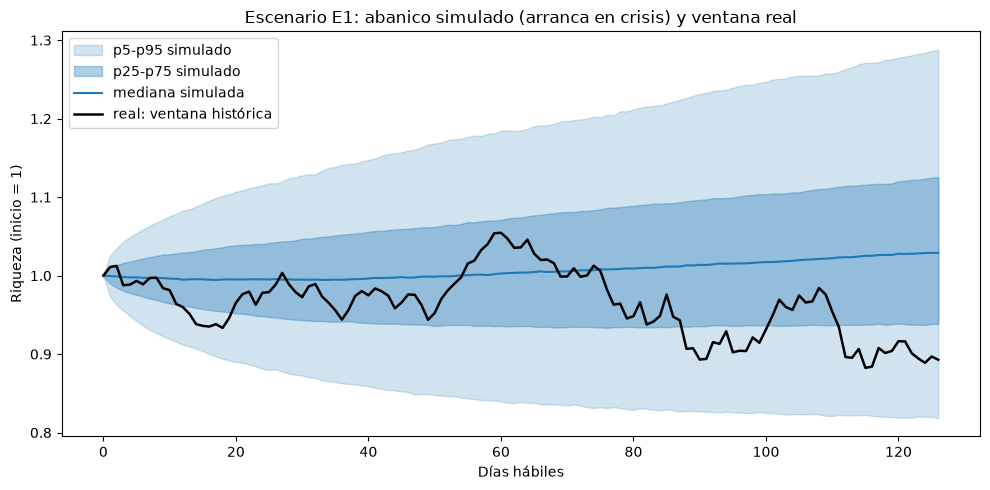

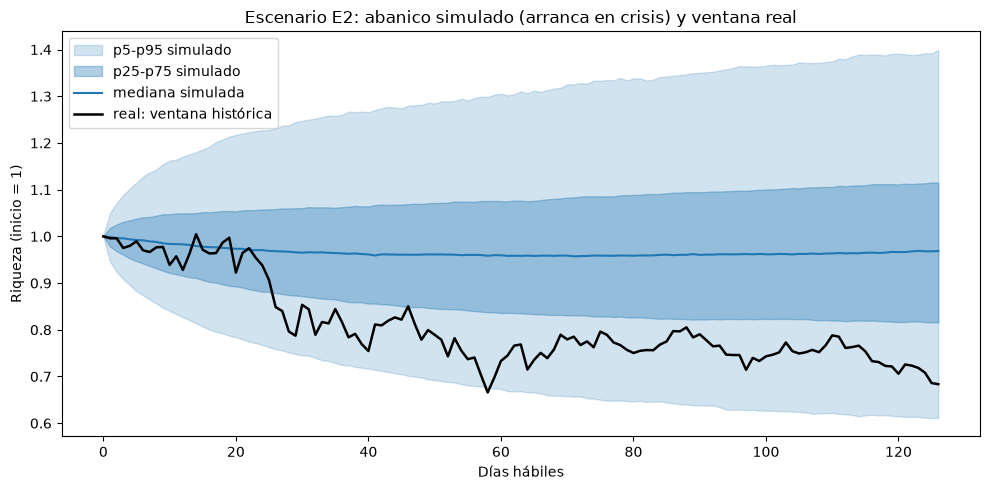

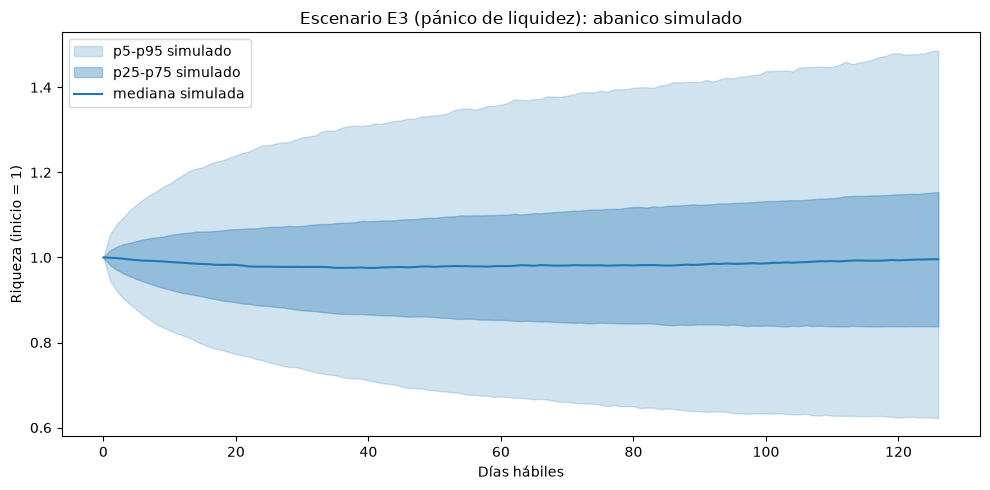

**Los abanicos.** La línea negra de E1 y E2 es la evolución real de la cartera en los primeros 126 días del periodo; queda dentro del abanico simulado pero en su mitad inferior. El abanico de E3 no tiene equivalente real: es un escenario hipotético.

In [41]:
display(esc.sensibilidad)
display(Markdown("**Sensibilidad (3.000 trayectorias por variante).** Cambiar la ventana de calibración, duplicar el ruido de la proxy de ENPH o quitar ENPH mueve el ES 99 % a 6 meses menos de 3 puntos porcentuales: las conclusiones no dependen de la proxy."))
fig_e = [("E1", esc.outcomes["E1"]), ("E2", esc.outcomes["E2"])]
for nombre, o in fig_e:
    figures.plot_abanico(o["fan"], o["real_w"], f"Escenario {nombre}: abanico simulado (arranca en crisis) y ventana real")
    plt.show()
figures.plot_abanico(esc.outcomes["E3"]["fan"], None, "Escenario E3 (pánico de liquidez): abanico simulado")
plt.show()
display(Markdown("**Los abanicos.** La línea negra de E1 y E2 es la evolución real de la cartera en los primeros 126 días del periodo; queda dentro del abanico simulado pero en su mitad inferior. El abanico de E3 no tiene equivalente real: es un escenario hipotético."))

## 7. Conclusiones, limitaciones y traza del pipeline
**Conclusiones para el Comité de Riesgos.**
1. El riesgo de la cartera **no es estable**: un régimen de crisis (alrededor de un sexto de los días) multiplica por ≈ 2 la volatilidad y más que duplica la correlación media; modelar con parámetros únicos subestima las pérdidas extremas.
2. **VaR y ES al 99 %** crecen de forma muy distinta según el tipo de crisis: la estanflación casi no aumenta la pérdida de cola, pero **elimina la cobertura de la renta fija**; el crédito y el pánico de liquidez la duplican.
3. La diversificación funciona **menos de lo que se cree** cuando más hace falta (la correlación sube), y el oro y los bonos son diversificadores, no seguros.

**Limitaciones y riesgo de modelo.** (i) Solo dos regímenes y la persistencia de la crisis simulada es menor que la de 2008; (ii) la dependencia se estima en 2012-2026 (370 días de crisis para 153 correlaciones): ruidosa; (iii) la proxy de ENPH es sintética;
(iv) los retornos diarios dentro de un estado son independientes (sin agrupamiento de volatilidad dentro del régimen); (v) las ventanas reales solapadas no son independientes, por lo que su VaR al 99 % es poco informativo; (vi) las colas derechas simuladas (GME, ENPH compuestos) son poco realistas y afectan a la media, no al VaR/ES;
(vii) los bonos se aproximan por duración y convexidad, sin diferencial ni *roll-down*. Recomendaciones de gestión: monitorizar el régimen con la probabilidad *filtrada* (sin *look-ahead*), fijar límites con **ES** y no solo con VaR, y no confiar en la cobertura de renta fija ante shocks de inflación.

In [42]:
resultados = build_results(reg, mar, cop, sim, esc)
ruta = write_results(resultados, trace)
print("Resultados guardados en", ruta)
display(trace.to_frame())

Resultados guardados en C:\Users\piett\OneDrive\Desktop\Pietro\Master MIAX\Clases\2.Introduccion a los Sistemas Financieros\Tareas\Riesgos\outputs\results.json


,paso,metodo,n_obs,seed,segundos,nota
0,factores,"Δ S&P, Δlog VIX, Δ(10a-2a), Δ OAS; z-score",5234,20260215,0.0134,
1,hmm,"GaussianHMM 2 estados, EM x10 inicios",5234,20260215,1.7197,loglik=-22838.0
2,probabilidades,suavizada (smoothing) y filtrada (forward),5234,20260215,0.9781,
3,estados_duros,umbral 0.5 + duración mínima 15 d,5234,20260215,0.0341,16.1% días en crisis
4,episodios,tabla de episodios de crisis y sensibilidad,17,20260215,0.1092,episodios de crisis
5,hmm_solo_sp500,contraste D-04: HMM solo sobre el S&P 500,5234,20260215,1.7010,
6,retornos_activos,equities+HYG (precio) y bonos (duración),92640,20260215,0.0160,18 activos
7,momentos,"media, vol, skew, curtosis por activo y estado",5234,20260215,0.0883,
8,ajuste_marginales,"Normal vs t por MLE, selección BIC",36,20260215,4.4912,35 t de 36
9,refugio,vol HYG y comportamiento de GLD,5234,20260215,0.0690,


### Anexo: teoría mínima
* **HMM.** El estado oculto sigue una cadena de Markov (la transición solo depende del estado actual); se estima maximizando la verosimilitud de los datos observados (Baum-Welch/EM) y devuelve la probabilidad de cada estado por día y la matriz de transición. *Filtering* = información hasta *t*; *smoothing* = toda la serie.
* **Cópula.** Por el teorema de Sklar, cualquier distribución conjunta = marginales + cópula. La t tiene dependencia de cola simétrica; la Gauss no.
* **VaR frente a ES.** El VaR (cuantil de la pérdida) no es subaditivo y no dice nada de la severidad más allá del umbral; el ES (media de las pérdidas ≥ VaR) es una medida coherente.
* **Por qué fallaron los modelos en 2022.** Supusieron normalidad y correlaciones estáticas bono-acción negativas; acciones y bonos cayeron a la vez.